# Notebook 06: Exploring the existing results

**Goal (about 2.5 hours, best split over two sessions: sections 1 to 9 in the first, exercises 1, 2, 4, 5 and 6 in the second; exercises 3 and 7 are optional stretch exercises, about 30 minutes more):** read the results Michael's pipeline produced for every station, account for every event (why it did or did not yield a measurement), and then interpret the measurements for the first time: what a fast direction says about the rock, where the stations' fast directions point on a map, how strong the anisotropy is, and whether anything changes during the swarm.

By the end you should be able to say, for each station with measurements:

- how many events it has, and which gates and cuts removed the rest;
- where its fast directions point, how tightly, and how that compares with the project's two hypotheses, the regional stress and the local structure;
- what its percent anisotropy is made of;
- why a change of dt through the swarm is not, by itself, a change in the rock.

This notebook describes and plots. Whether a difference is larger than chance (error bars that respect how the events cluster in time, permutation tests, the sensitivity to thresholds) is notebook 07's job; where a question here needs that, it says so. Words in **bold** are defined where they first appear; section 10 collects them in a glossary.

From here on you work with the results CSVs in `results/`: one row per catalog event per station. Nothing is dropped; the `stage` column says where each event stopped.

> **Note on STAR.** STAR's vertical and north channels are exchanged (notebook 02; README, *Known facts*), and its original results file was computed on the channels as labelled, so the pipeline's "horizontals" were really the vertical and east records. This notebook uses the research pipeline's re-run on waveforms rotated to true vertical, north and east (**Z/N/E**), read with `paths.station_results_csv("STAR", oriented=True)`. The re-run also screens out the 33 events whose S wave **clipped**: the ground moved more than the digitizer's largest count can record (about 2.0e4 counts at STAR), so the recorded wave is cut flat at that level and its shape is wrong. Section 7 compares the original and corrected results. The other stations' channels point where their names say, so their original files are used.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats, reference
print("repo:", REPO)

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials


## 1. What a results file holds

The files share their columns, with two exceptions: STAR's re-run adds `orientation` and `clip_fraction`, and a station where no event reached the measurement has no measurement columns at all (pandas writes only the columns some row filled; `quality` adds them back, empty). Here is the first row of STAR's file:

In [2]:
STATIONS = ["STAR", "RCM", "MILD", "LON", "PANH", "OBSR", "PARA", "RER", "COPP"]
# STAR: the research pipeline's re-run on corrected components (the note above); the others as archived
res = {s: pd.read_csv(paths.station_results_csv(s, oriented=(s == "STAR"))) for s in STATIONS}
print("rows (catalog events) per station:", {s: len(r) for s, r in res.items()})
res["STAR"].iloc[0]          # the first row of STAR's file, every column

rows (catalog events) per station: {'STAR': 1196, 'RCM': 509, 'MILD': 685, 'LON': 1172, 'PANH': 414, 'OBSR': 139, 'PARA': 749, 'RER': 450, 'COPP': 348}


evid                                                                  61504363
station                                                                   STAR
stage                                                                       ok
orientation                  EHZ az=0 dip=0 (fix); EHN az=0 dip=-90 (fix); ...
back_azimuth                                                         80.287841
rectilinearity                                                        0.644608
incidence_angle_jurkevics                                            57.696311
incidence_angle                                                      25.207142
travel_time_s                                                         1.822654
snr_horizontal                                                        3.293473
filter_band                                                        (5.0, 10.0)
clip_fraction                                                           0.1975
phi                                                 

| column | meaning | from |
| --- | --- | --- |
| `evid`, `station` | PNSN event id and station code | catalog |
| `stage` | where the event stopped: `ok`, or the first gate it failed (section 2) | pipeline |
| `orientation` | STAR only: how each channel was rotated to true Z/N/E; `fix` is a known correction (`data.ORIENTATION_FIXES`), `metadata` the archived azimuth and dip | `data.get_event_stream` |
| `back_azimuth` | the **back azimuth**: the direction from the station towards the earthquake, degrees clockwise from north (notebook 02, section 6) | coordinates |
| `rectilinearity` | how close the P wave's **particle motion** (the path the ground traces in three dimensions as the wave passes) is to a straight line: 1 for a perfect line, 0 for no preferred direction. It comes from the eigenvalues of the three components' covariance in a 0.12 s window starting just before the P pick (**Jurkevics**, 1988) | waveforms |
| `incidence_angle_jurkevics` | the P wave's angle from vertical, from the same eigenvalue analysis (the **Jurkevics angle**) | waveforms |
| `incidence_angle` | the S ray's angle from vertical at the station, from ray tracing (below) | model |
| `travel_time_s` | the S wave's travel time from the earthquake to the station, s, from the same ray tracing | model |
| `snr_horizontal` | the S-wave SNR in the chosen band: S against the P coda (notebook 03, section 5) | waveforms |
| `filter_band` | the band the filter bank chose, (low, high) in Hz (notebook 03, section 6) | waveforms |
| `clip_fraction` | STAR only: the peak counts in the first second after S over the clip level, 2.0e4 counts | waveforms |
| `phi` | the fast direction, degrees clockwise from north. It is an axis: phi and phi + 180 are the same direction (section 5) | SWSPy |
| `dt` | the slow wave's delay, s, in steps of `measure.dt_step` (two samples; notebook 03, section 8) | SWSPy |
| `phi_error`, `dt_error` | the **formal errors**: half-widths of the 99.7 percent confidence region of SWSPy's grid search (notebooks 05 and 07) | SWSPy |
| `quality` | **Q_w** (Wüstefeld et al., 2010): compares the answers of two different methods. Near +1 when both find the same split, near -1 when both say the wave did not split (a null, section 4), near 0 when they disagree (notebook 04) | SWSPy |
| `dominant_period` | the period of the strongest frequency in the filtered S wave, s (notebook 03, section 7) | waveforms |
| `success` | True when SWSPy returned finite phi and dt | pipeline |
| `pct_anisotropy` | 100 × dt / `travel_time_s` (sections 4 and 8) | derived |
| `datetime`, `magnitude` | origin time (UTC) and PNSN magnitude | catalog |
| `error`, `traceback` | the Python error, for `fail_exception` rows | pipeline |

Two columns come from a model, not from the data. `incidence_angle` and `travel_time_s` are the result of **ray tracing**: following the path an S wave takes from the earthquake to the station through a **velocity model**, a three-dimensional map of how fast S waves travel under the volcano (here the iMUSH P-wave model divided by 1.73; README). The research pipeline did the ray tracing; the repo stores its answers. Keep that in mind whenever a number depends on them: the incidence gate (section 2) and percent anisotropy (section 8) do.

## 2. The funnel: attempted, successful, filtered

Two layers of choices stand between a catalog event and a fast direction, both written down in `rainier_sws/quality.py`.

The **pre-processing gates** decide whether a measurement is even attempted. In the pipeline's order, and with the `stage` an event gets when it fails:

| stage | the event fails because | parameter |
| --- | --- | --- |
| `fail_clipped` | its S wave clipped (STAR only: the only station with a known clip level) | `PreGates.clip_fraction_max` |
| `fail_rectilinearity` | its P wave's particle motion is not line-like enough to trust the channels | `PreGates.rectilinearity_min` |
| `fail_incidence` | its ray arrives too far from vertical: outside the **shear-wave window** (section 4; notebook 04) | `PreGates.incidence_max_deg` |
| `fail_snr` | S is not at least twice the P coda in its best band (notebook 03, section 5) | `PreGates.snr_min` |

Three more stages are not gates: `fail_no_result` (SWSPy ran but returned nothing), `fail_exception` (the code raised an error; the message is in `error`) and `missing_channel` (no three-component record in the waveform set).

The **post-processing filter** then decides which of the successful measurements to trust. It has five cuts (`quality.PostFilter`): SNR at least 2; Q_w at least 0.75; dt_error at most 0.05 s; phi_error at most 20 degrees; and dt at most half the dominant period, because a longer delay is probably a cycle skip (notebook 03, section 7). The funnel counts the events that survive each layer: "successful" means the pipeline reached the end and returned finite phi and dt, "filtered" that the measurement also passed all five cuts.

In [3]:
print("pre-processing gates:  ", quality.DEFAULT_PRE)
print("post-processing filter:", quality.DEFAULT_POST)

pre-processing gates:   PreGates(clip_fraction_max=0.97, rectilinearity_min=0.5, incidence_max_deg=45.0, snr_min=2.0)
post-processing filter: PostFilter(snr_min=2.0, qw_min=0.75, dt_error_max=0.05, phi_error_max=20.0, dt_period_fraction=0.5)


In [4]:
funnel = pd.DataFrame({s: quality.funnel(r) for s, r in res.items()}).T
funnel

,attempted,successful,filtered
STAR,1196,659,194
RCM,509,274,32
MILD,685,107,24
LON,1172,670,38
PANH,414,0,0
OBSR,139,1,0
PARA,749,0,0
RER,450,0,0
COPP,348,0,0


stage   ok  fail_incidence  fail_rectilinearity  fail_snr  fail_clipped  fail_no_result  fail_exception  missing_channel
STAR   659              47                    1         9            33              88              64              295
RCM    274             153                   44         2             0              30               4                2
MILD   107             546                    1         5             0              18               4                4
LON    670             376                    1        19             0              91              11                4
PANH     0             413                    1         0             0               0               0                0
OBSR     1             137                    0         0             0               1               0                0
PARA     0             746                    2         0             0               0               1                0
RER      0             405      

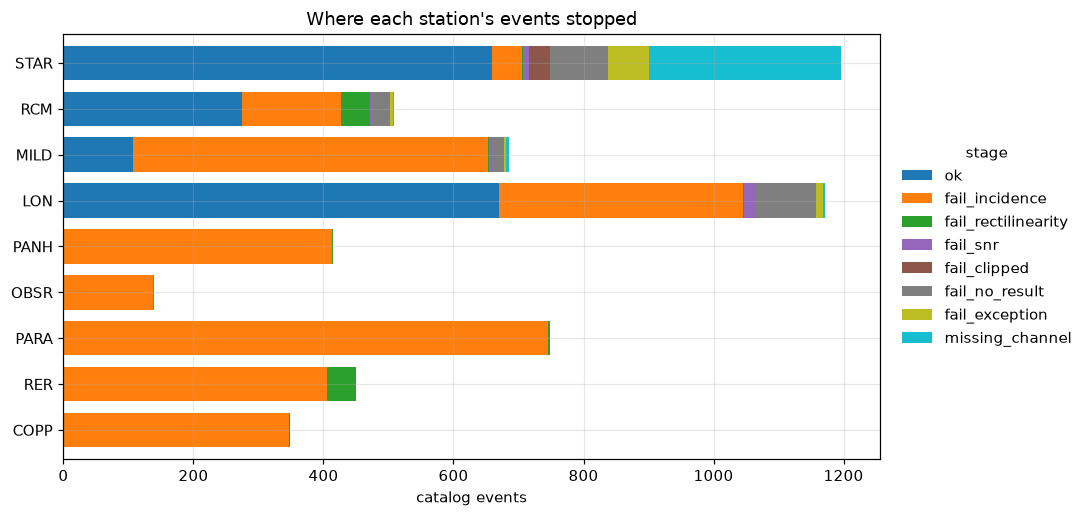

In [5]:
stages = pd.DataFrame({s: quality.stage_counts(r) for s, r in res.items()}).fillna(0).astype(int).T
order = ["ok", "fail_incidence", "fail_rectilinearity", "fail_snr", "fail_clipped", "fail_no_result", "fail_exception", "missing_channel"]
stages = stages[[c for c in order if c in stages] + [c for c in stages if c not in order]]   # every stage, none dropped
ax = stages.plot.barh(stacked=True, figsize=(10, 4.8), colormap="tab10", width=0.75)
ax.invert_yaxis()
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, title="stage")
ax.set(xlabel="catalog events", ylabel="", title="Where each station's events stopped")
plt.tight_layout()
print(stages.to_string())

This is the picture behind the README's *Known facts*: PANH, OBSR, PARA, RER and COPP produce almost nothing, and the plot shows exactly why: **essentially every event fails the incidence gate** (RER also loses 45 events to the rectilinearity check, which comes first). Through the velocity model used for ray tracing, every S wave reaches those stations more than 45 degrees from vertical. That is a known, understood outcome, not a bug to find. MILD loses 546 of its 685 events the same way, and even LON, whose gate used the Jurkevics angle instead (exercise 2), loses 376.

Whether that is the *right* conclusion depends on two choices made upstream: the velocity model that produced the angles, and the 45-degree cutoff itself. Both are thresholds to benchmark (notebook 07), not facts; exercise 3 looks at the angles.

Two more stages appear for STAR. The corrected re-run attempted every STAR pair of the strict catalog (1196), where the original run attempted only the 903 whose P and S picks both have quality 0.75 or more; 295 of the 1196 have no three-component record in the waveform set (`missing_channel`). And 33 events stop at `fail_clipped` (the note at the top).

## 3. Distributions of the measured quantities (STAR)

Before any filtering, look at everything the pipeline returned. Histograms of phi, dt, their formal errors, Q_w and the SNR show what the raw population looks like and where the post-processing cuts fall. Two reminders: the formal errors are not error bars that shrink with SNR, but the half-width of the region of the grid search that fits almost as well as the best answer (notebooks 05 and 07); and Q_w compares two methods, so a low Q_w means they disagree.

STAR, 659 successful: Q_w exactly 0 for 115, phi_error 89 deg or more for 62, dt_error at its floor of 0.01 s for 321
filtered: dt (s) and how many events have it: {0.02: 43, 0.04: 12, 0.06: 116, 0.08: 23}


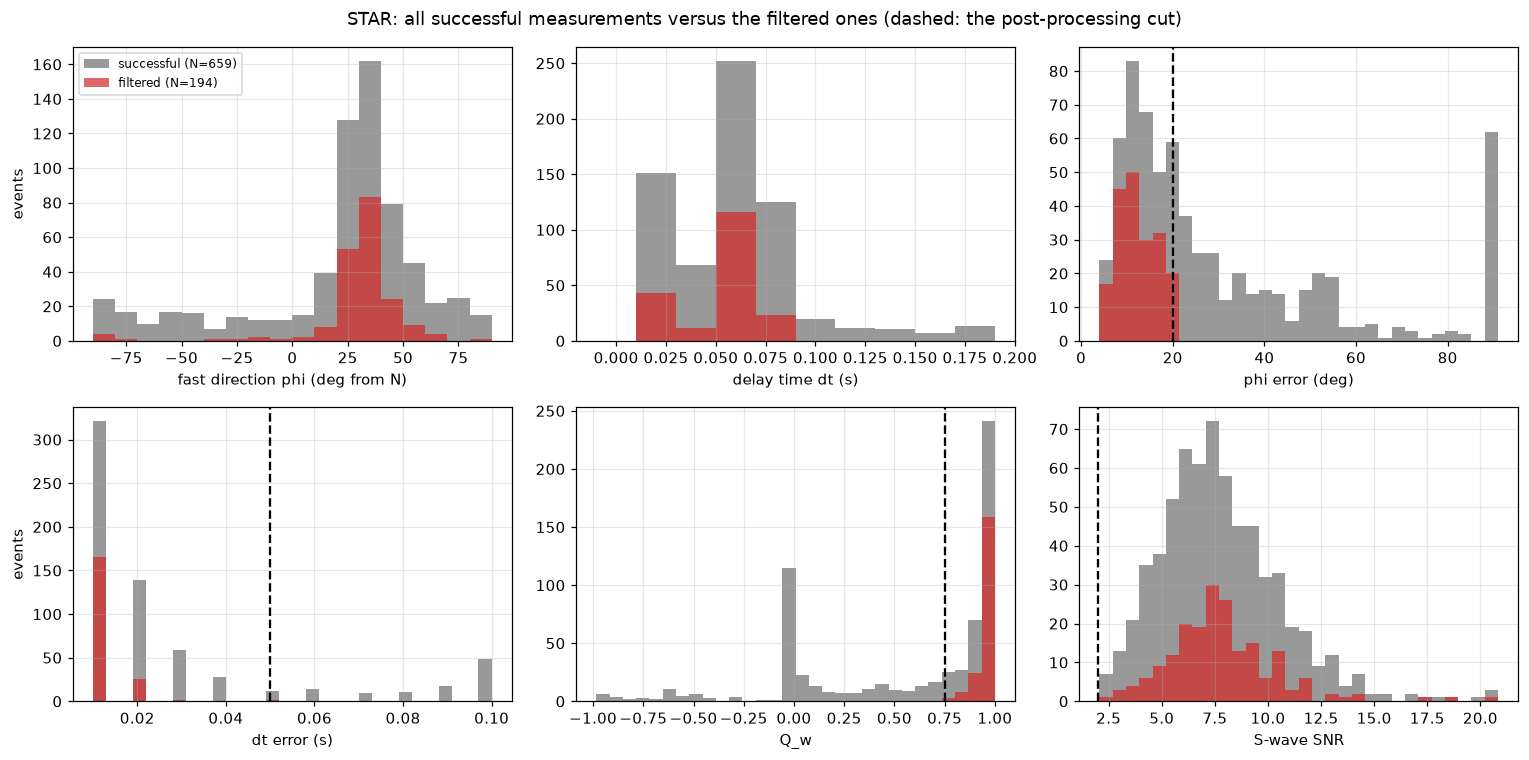

In [6]:
def hist_panel(r, title):
    """Histograms of six result columns: every successful measurement (grey) and the filtered ones (red)."""
    ok = quality.successful(r); kept = quality.post_filtered(r)
    g = quality.DEFAULT_POST
    cols = [("phi", "fast direction phi (deg from N)", None), ("dt", "delay time dt (s)", None),
            ("phi_error", "phi error (deg)", g.phi_error_max), ("dt_error", "dt error (s)", g.dt_error_max),
            ("quality", "Q_w", g.qw_min), ("snr_horizontal", "S-wave SNR", g.snr_min)]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, (c, lab, cut) in zip(axes.ravel(), cols):
        if c == "phi":
            bins = np.arange(-90, 91, 10)
        elif c == "dt":
            bins = np.arange(-0.01, ok.dt.max() + 0.02, 0.02)         # one bin per 0.02 s step
        else:
            bins = np.histogram_bin_edges(ok[c].dropna(), bins=30)     # the same bins for both histograms
        ax.hist(ok[c].dropna(), bins=bins, color="0.6", label=f"successful (N={len(ok)})")
        ax.hist(kept[c].dropna(), bins=bins, color="tab:red", alpha=0.7, label=f"filtered (N={len(kept)})")
        if cut is not None:
            ax.axvline(cut, color="k", ls="--")
        ax.set_xlabel(lab)
    for ax in axes[:, 0]:
        ax.set_ylabel("events")
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{title} (dashed: the post-processing cut)"); plt.tight_layout()

hist_panel(res["STAR"], "STAR: all successful measurements versus the filtered ones")
ok = quality.successful(res["STAR"])
print(f"STAR, {len(ok)} successful: Q_w exactly 0 for {(ok.quality == 0).sum()}, phi_error 89 deg or more for "
      f"{(ok.phi_error >= 89).sum()}, dt_error at its floor of 0.01 s for {np.isclose(ok.dt_error, 0.01).sum()}")
print("filtered: dt (s) and how many events have it:", quality.post_filtered(res["STAR"]).dt.round(2).value_counts().sort_index().to_dict())

Read the panels together:

- **phi.** The successful measurements already lean north-north-east, with a broad background at every angle; the filtered ones are concentrated between 20 and 50 degrees (section 5 measures how tightly).
- **dt** comes in steps of 0.02 s (two samples at 100 Hz; notebook 03, section 8), so the filtered delays take four values only: 43 events at 0.02 s, 12 at 0.04 s, 116 at 0.06 s and 23 at 0.08 s. Which value an event gets depends strongly on its filter band (notebook 03, exercise 3; section 9 here).
- **The formal errors pile up at their limits.** dt_error sits at its floor of 0.01 s, half a step, for 321 of the 659 successful measurements, and phi_error reaches 89 degrees or more for 62: the region of good fits fills the whole grid, so phi is not constrained at all.
- **Q_w** is exactly 0 for 115 measurements, a spike that looks like a capped value rather than a score (README). The filter keeps only the cluster near 1.
- **SNR**: the post-processing cut at 2 removes nothing, because the pre-processing gate already required it (exercise 1).

Whether a delay of one step is physically meaningful is a fair question to keep asking; section 8 comes back to it.

## 4. What a fast direction means

Notebook 04 built the measurement on a synthetic wave. Here is what its two numbers say about the rock, which is what the project wants from them.

**Why rock is anisotropic.** A material is **anisotropic** when a wave's speed depends on the direction the wave travels or shakes in. The upper few kilometres of a volcano are full of **cracks**: thin gaps, millimetres to metres across, mostly filled with water or gas. A crack is soft to shearing across it and stiff along it, so an S wave that shakes the rock along a set of aligned cracks travels faster than one that shakes it across them. That is the split: the fast direction phi gives the orientation of the cracks, and dt grows with how many cracks there are and how far the wave travels among them.

**What lines the cracks up.** Two things, and they are the project's two hypotheses (README):

- **Stress.** Rock underground is squeezed from all sides, but not equally. The horizontal direction in which the squeeze is largest is the **maximum horizontal compressive stress**, SHmax. Cracks at right angles to SHmax are pressed shut, while cracks parallel to it stay open, held open by the fluid inside them. In **stress-aligned** anisotropy, phi is therefore parallel to SHmax (Crampin and Peacock, 2008). Under Rainier the regional SHmax points about north-east (`reference.REGIONAL_COMPRESSION_AZ`), and under the summit the weight of the edifice adds a vertical load that can change the horizontal stresses locally.
- **Structure.** Faults, **dikes** (sheets of once-molten rock that cut through older rock), fractured zones and layered lava flows have a direction of their own, their **strike**: the direction of the line they make with a horizontal surface. Cracks and minerals lined up with them make **structural** anisotropy, with phi parallel to the strike whatever the present stress. The 2009 swarm lit up a near-vertical structure about 850 m long beneath the summit (Shelly, Moran and Thelen, 2013); `reference.STRUCTURE_2009_STRIKE` gives its strike, also about north-east.

Panels (a) and (b) sketch the two cases with example directions; panel (c) draws the two **reference directions** at Rainier with STAR's fast direction (section 5).

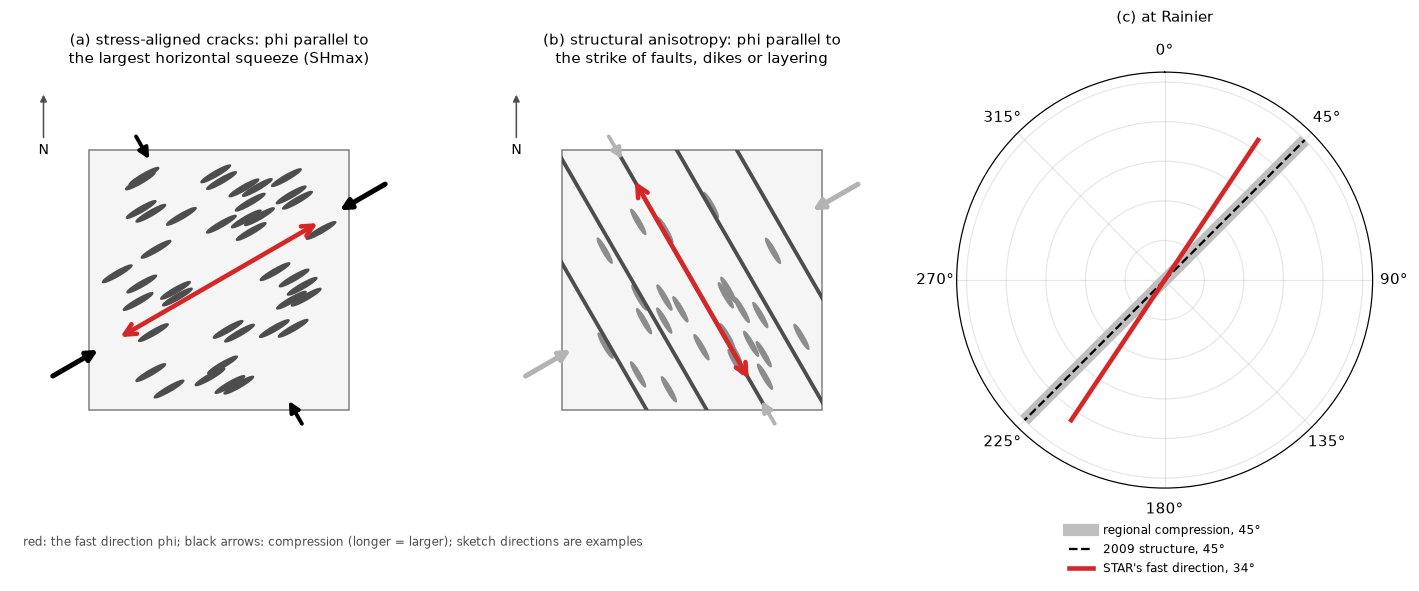

In [7]:
from matplotlib.patches import Ellipse, Rectangle
from matplotlib.lines import Line2D

def unit(az):
    """East and north components of a unit vector at azimuth az (deg clockwise from north)."""
    return np.sin(np.deg2rad(az)), np.cos(np.deg2rad(az))

def squeeze(ax, az, size, color):
    """Two arrows pushing inwards along azimuth az: a compressive stress (longer arrows, larger stress)."""
    ux, uy = unit(az)
    for sgn in (-1, 1):
        ax.annotate("", xy=(sgn * 1.05 * ux, sgn * 1.05 * uy), xytext=(sgn * (1.05 + size) * ux, sgn * (1.05 + size) * uy),
                    arrowprops=dict(arrowstyle="-|>", color=color, lw=1.5 + 4 * size, mutation_scale=14))

def fast_arrow(ax, az):
    ux, uy = unit(az)
    ax.annotate("", xy=(0.9 * ux, 0.9 * uy), xytext=(-0.9 * ux, -0.9 * uy),
                arrowprops=dict(arrowstyle="<->", color="tab:red", lw=3, mutation_scale=18))

def axis_line(ax, az, r, **kw):
    """An axis through the centre of a polar plot (two radial segments, so it stays straight)."""
    for a in (az, az + 180):
        ax.plot([np.deg2rad(a)] * 2, [0, r], **kw)

SHMAX, STRIKE = 60, 150          # example directions for the sketch, deg clockwise from north
rng = np.random.default_rng(1)
fig = plt.figure(figsize=(13, 4.8))
ax_a, ax_b = fig.add_subplot(1, 3, 1), fig.add_subplot(1, 3, 2)
for ax in (ax_a, ax_b):
    box = Rectangle((-1, -1), 2, 2, fc="0.96", ec="0.5")
    ax.add_patch(box)
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.6, 1.6), aspect="equal", xticks=[], yticks=[])
    ax.grid(False)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.annotate("N", xy=(-1.35, 1.45), xytext=(-1.35, 1.05), ha="center", va="top", fontsize=9,
                arrowprops=dict(arrowstyle="-|>", color="0.3", lw=1))
# (a) cracks parallel to the largest squeeze stay open; the others are pressed shut
for x, y in rng.uniform(-0.85, 0.85, (40, 2)):
    ax_a.add_patch(Ellipse((x, y), 0.26, 0.04, angle=90 - SHMAX, color="0.3"))
squeeze(ax_a, SHMAX, 0.45, "k"); squeeze(ax_a, SHMAX + 90, 0.25, "k")
fast_arrow(ax_a, SHMAX)
ax_a.set_title("(a) stress-aligned cracks: phi parallel to\nthe largest horizontal squeeze (SHmax)", fontsize=10)
# (b) faults or dikes with a strike of their own, and cracks along them; the stress is still there (grey)
ux, uy = unit(STRIKE); px, py = unit(STRIKE + 90)
for off in np.linspace(-0.8, 0.8, 5):
    line, = ax_b.plot([off * px - 1.5 * ux, off * px + 1.5 * ux], [off * py - 1.5 * uy, off * py + 1.5 * uy], color="0.3", lw=2.5)
    line.set_clip_path(box)
for x, y in rng.uniform(-0.85, 0.85, (25, 2)):
    ax_b.add_patch(Ellipse((x, y), 0.22, 0.035, angle=90 - STRIKE, color="0.55"))
squeeze(ax_b, SHMAX, 0.45, "0.7"); squeeze(ax_b, SHMAX + 90, 0.25, "0.7")
fast_arrow(ax_b, STRIKE)
ax_b.set_title("(b) structural anisotropy: phi parallel to\nthe strike of faults, dikes or layering", fontsize=10)
# (c) Rainier's two reference directions, and STAR's fast direction
ax_c = fig.add_subplot(1, 3, 3, projection="polar")
ax_c.set_theta_zero_location("N"); ax_c.set_theta_direction(-1)
star_phi, star_R = stats.axial_mean(quality.post_filtered(res["STAR"]).phi)
axis_line(ax_c, reference.REGIONAL_COMPRESSION_AZ, 1.0, color="0.75", lw=8, solid_capstyle="butt")
axis_line(ax_c, reference.STRUCTURE_2009_STRIKE, 1.0, color="k", lw=1.5, ls="--")
axis_line(ax_c, star_phi, 0.85, color="tab:red", lw=3)
ax_c.set(ylim=(0, 1.05), yticklabels=[]); ax_c.set_title("(c) at Rainier", fontsize=10, pad=14)
ax_c.legend(handles=[Line2D([], [], color="0.75", lw=8, label=f"regional compression, {reference.REGIONAL_COMPRESSION_AZ:.0f}°"),
                     Line2D([], [], color="k", lw=1.5, ls="--", label=f"2009 structure, {reference.STRUCTURE_2009_STRIKE:.0f}°"),
                     Line2D([], [], color="tab:red", lw=3, label=f"STAR's fast direction, {star_phi:.0f}°")],
            loc="upper center", bbox_to_anchor=(0.5, -0.06), frameon=False, fontsize=8)
fig.text(0.02, 0.02, "red: the fast direction phi; black arrows: compression (longer = larger); "
         "sketch directions are examples", fontsize=8, color="0.3")
plt.tight_layout()

**At Rainier the two reference directions coincide.** Both point about north-east, so a fast direction near north-east, which is what STAR measures, fits both hypotheses equally well: at STAR the azimuth alone cannot separate them. Other observations can, because the two hypotheses predict different things for them:

| look at | if stress lines up the cracks | if structure does |
| --- | --- | --- |
| phi from station to station | the same wherever the stress is the same; it can bend near the volcano, where the weight of the edifice and the topography change the local stress | follows each station's local structure, so it can differ between stations a few kilometres apart |
| phi through time | can rotate when stress or fluid pressure changes. When fluid pressure nearly opens every crack, fast and slow can even exchange, a 90-degree flip (Crampin and Peacock, 2008). Fast directions under Ruapehu volcano, New Zealand, changed between eruptions (Gerst and Savage, 2004) | fixed over the weeks of a swarm |
| percent anisotropy through time | changes with the number of open cracks, so with fluid pressure | constant |

Nature need not choose one: near the San Andreas fault, Boness and Zoback (2006) found stress-aligned anisotropy in some places and fault-parallel, structural anisotropy in others. Sections 6 and 9, and exercise 6, put these predictions to the data.

**Percent anisotropy and path averaging.** dt builds up along the whole stretch of the ray that runs through anisotropic rock. If the rock is equally anisotropic all along the path, dt grows in proportion to the path, and dividing by the travel time gives a property of the rock alone, the **percent anisotropy**, 100 × dt / travel time: in the simplest case, the percentage by which the fast S wave is faster than the slow one. It is **path-averaged**: one number for the whole path, which cannot say where along it the cracks are. If instead the anisotropy is concentrated in a shallow layer under the station (common, because cracks close as the pressure grows with depth), dt is the same for long and short paths, and percent anisotropy falls with path length even when the rock under every station is the same. Section 8 looks.

**Two reminders from notebook 04.**

- **Nulls.** A wave that arrives already shaking along the fast or the slow direction does not split, and the measurement then reports that direction as phi with little meaning: a **null**. For a local earthquake, the direction the S wave first shakes in, its **source polarization**, is set by the earthquake's focal mechanism (the orientation of the fault that slipped and the direction of slip), so nulls line up with the source polarization (`Measurement.src_pol`), not with the back azimuth. Of STAR's 194 filtered events, 32 lie within 20 degrees of their source polarization or its perpendicular, fewer than the 44 percent that random directions would give (README; notebook 07).
- **The shear-wave window.** Only rays that reach the surface steeply enough, within about 35 degrees of vertical (the **critical angle**, sin⁻¹(Vs/Vp) for a Vp/Vs of 1.73), keep the S wave's particle motion undistorted by the free surface. The pipeline's gate allows 45 degrees, the usual allowance for slower rock near the surface, which bends rays towards the vertical.

## 5. Rose diagrams

The standard display for fast directions is a **rose diagram**: a histogram drawn on a circle, mirrored because phi is an axis (30 and 210 degrees are the same orientation). Because of that, the ordinary mean does not work: the mean of 10 and 170 degrees, two nearly identical north-south axes, would come out east-west. The **axial mean** doubles every angle (so phi and phi + 180 become the same angle), averages the corresponding unit vectors, and halves the direction of the result (Fisher, 1993; `stats.axial_mean`). The length of that average vector is the **mean resultant length** R: 1 when every phi is the same, 0 when they point every way equally. In the roses below the black line is the axial mean and the dashed line the reference direction of section 4.

           N axial mean (deg)    R circular SD (deg) Rayleigh p
station                                                        
STAR     194             33.7 0.86              15.6    6.6e-61
RCM       32            151.2 0.85              16.2    2.4e-10
MILD      24            110.4 0.42              37.7    1.3e-02


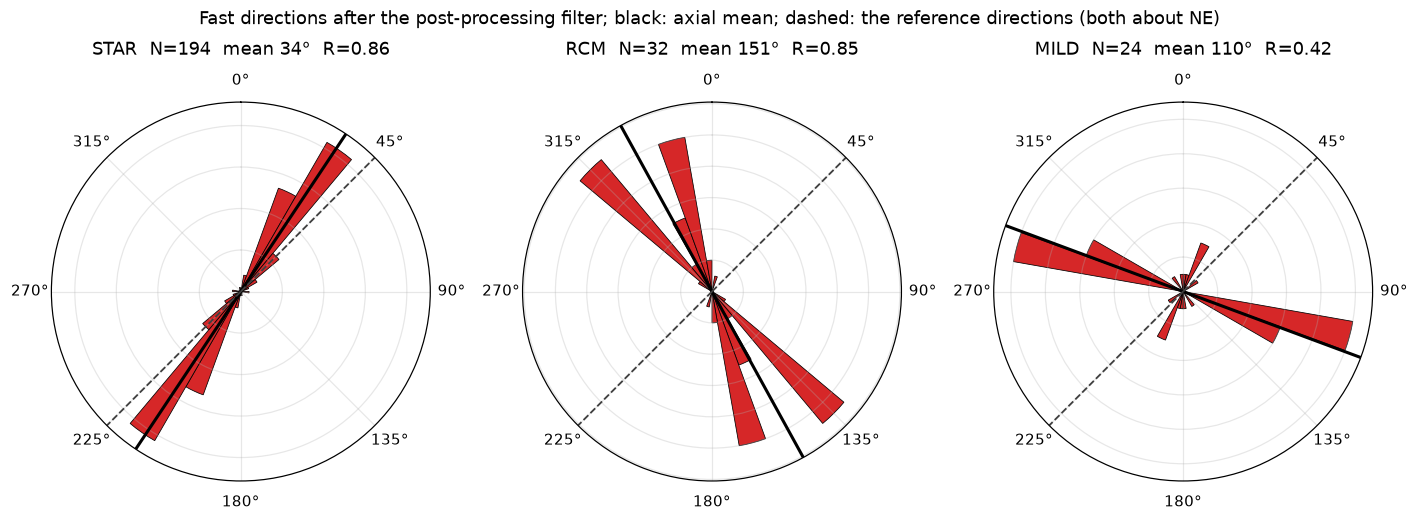

In [8]:
def rose(ax, phi_deg, bin_deg=10, color="tab:red", title="", ref=reference.REGIONAL_COMPRESSION_AZ):
    """Rose diagram of fast directions (an axis, so mirrored); black: the axial mean; dashed: a reference axis."""
    phi = measure.phi_0_180(np.asarray(phi_deg))
    bins = np.arange(0, 181, bin_deg)
    counts, _ = np.histogram(phi, bins=bins)
    theta = np.deg2rad(np.concatenate([bins[:-1], bins[:-1] + 180]))
    ax.bar(theta, np.concatenate([counts, counts]), width=np.deg2rad(bin_deg), bottom=0, color=color, edgecolor="k", lw=0.5, align="edge")
    top = max(counts.max(), 1) * 1.1
    m, _ = stats.axial_mean(phi)
    for a in (m, m + 180):
        ax.plot([np.deg2rad(a)] * 2, [0, top], "k-", lw=2)
    if ref is not None:
        for a in (ref, ref + 180):
            ax.plot([np.deg2rad(a)] * 2, [0, top], color="0.25", ls="--", lw=1.2)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_yticklabels([]); ax.set_ylim(0, top)
    ax.set_title(title, pad=12)

fig = plt.figure(figsize=(13, 4.8))
rows = []
for i, s in enumerate(["STAR", "RCM", "MILD"]):
    kept = quality.post_filtered(res[s])
    m, R = stats.axial_mean(kept.phi)
    rose(fig.add_subplot(1, 3, i + 1, projection="polar"), kept.phi, title=f"{s}  N={len(kept)}  mean {m:.0f}°  R={R:.2f}")
    rows.append({"station": s, "N": len(kept), "axial mean (deg)": m, "R": R,
                 "circular SD (deg)": stats.axial_std(kept.phi), "Rayleigh p": stats.rayleigh_test(kept.phi)[1]})
fig.suptitle("Fast directions after the post-processing filter; black: axial mean; dashed: the reference directions (both about NE)")
plt.tight_layout()
print(pd.DataFrame(rows).set_index("station").to_string(formatters={"axial mean (deg)": "{:.1f}".format, "R": "{:.2f}".format,
                                                                   "circular SD (deg)": "{:.1f}".format, "Rayleigh p": "{:.1e}".format}))

STAR's fast directions cluster tightly around 34 degrees, north-north-east (R = 0.86, N = 194). RCM, with a sixth as many events, is as tightly clustered (R = 0.85) around 151 degrees, north-north-west; MILD has the fewest events and a broad spread around west-north-west (110 degrees, R = 0.42).

Two more statistics in the table:

- The **circular standard deviation**, √(−2 ln R) / 2 for axes, in degrees, is the spread of single measurements around the mean: 16 degrees at STAR and RCM, 38 at MILD. It is not the uncertainty of the mean, which is much smaller (notebook 07).
- The **Rayleigh test** asks how likely an R this large would be if the same number of axes were scattered at random; that probability is the **p-value**. All three p-values are far below the conventional 0.05 (MILD's is 0.013), so each station has a preferred axis. A preferred axis is not necessarily a correct one (section 7, exercise 2).

None of these means has an error bar yet; that is notebook 07.

## 6. A map of the fast directions

Put the means on the map of notebook 02. At each station with filtered measurements, the red bar points along the axial mean and is longer the larger R is; the white bar under it points along the reference directions. If one regional stress lined up the cracks everywhere, every red bar would lie on its white bar.

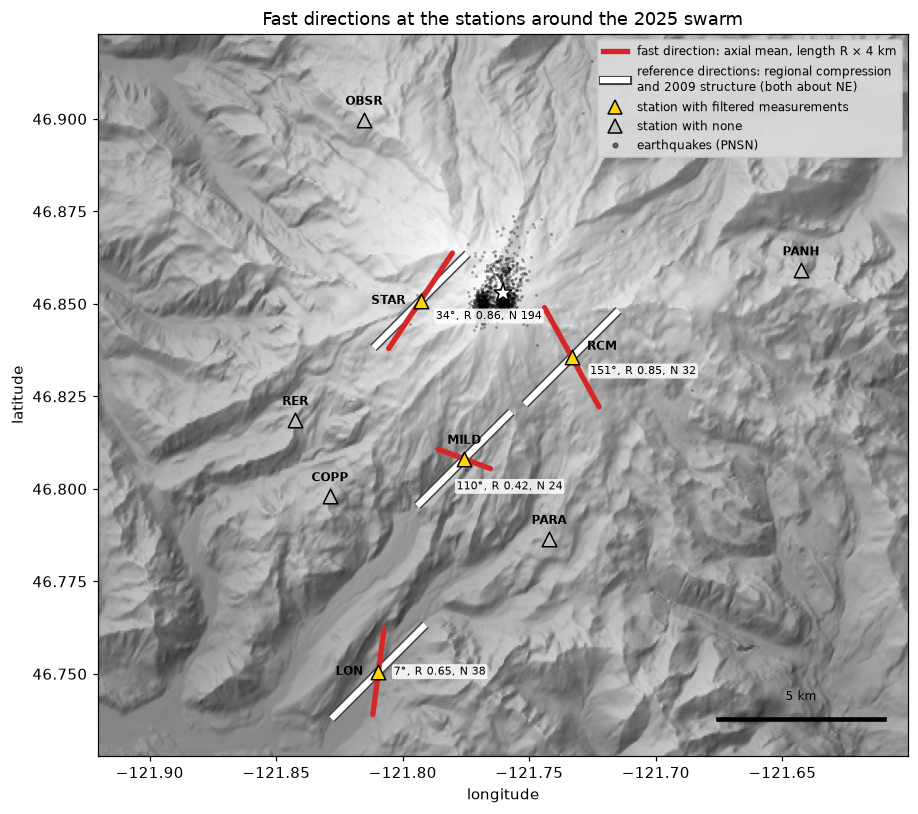

In [9]:
from matplotlib.colors import LightSource
import matplotlib.patheffects as pe
from obspy.geodetics import gps2dist_azimuth

elev, extent = data.load_topography()
summit = (46.8529, -121.7604)                                   # lat, lon (notebook 02)
km_lat = 111.32                                                 # km per degree of latitude
km_lon = km_lat * np.cos(np.deg2rad(summit[0]))                 # km per degree of longitude here
relief = LightSource(azdeg=315, altdeg=45).shade(elev, cmap=plt.cm.gray, vmin=-2000, vmax=5000, blend_mode="soft", vert_exag=2,
                                                 dx=(extent[1] - extent[0]) / elev.shape[1] * km_lon * 1e3,
                                                 dy=(extent[3] - extent[2]) / elev.shape[0] * km_lat * 1e3)
sta = data.load_stations().set_index("station")
events = data.load_events()

def map_axis(ax, lon, lat, az, length_km, **kw):
    """Draw an axis of length_km centred on (lon, lat) along azimuth az."""
    e, n = np.sin(np.deg2rad(az)) * length_km / 2, np.cos(np.deg2rad(az)) * length_km / 2
    ax.plot([lon - e / km_lon, lon + e / km_lon], [lat - n / km_lat, lat + n / km_lat], **kw)

BAR_KM = 4.0                                                    # length of a fast-direction bar with R = 1
LABEL_AT = {"STAR": (-10, 0, "right"), "RCM": (10, 3, "left"), "LON": (-10, 0, "right")}   # names and numbers clear of the bars
NUMBERS_AT = {"STAR": (10, -10), "RCM": (12, -9), "MILD": (-5, -18), "LON": (10, 0)}
fig, ax = plt.subplots(figsize=(9.5, 7.5))
ax.imshow(relief, extent=extent, zorder=0)
ax.scatter(events.lon, events.lat, s=4, c="k", alpha=0.3, lw=0, zorder=2)
ax.plot(summit[1], summit[0], "*", color="w", mec="k", ms=13, zorder=6)
for s in STATIONS:
    lat, lon = sta.loc[s, "lat"], sta.loc[s, "lon"]
    kept = quality.post_filtered(res[s])
    ax.scatter(lon, lat, marker="^", s=90, c="#FFD700" if len(kept) else "0.75", edgecolor="k", zorder=5)
    dx_, dy_, ha_ = LABEL_AT.get(s, (0, 8, "center"))
    ax.annotate(s, (lon, lat), xytext=(dx_, dy_), textcoords="offset points", ha=ha_, va="center" if dy_ == 0 else "bottom",
                fontsize=8, weight="bold", zorder=7)
    if len(kept):
        m, R = stats.axial_mean(kept.phi)
        map_axis(ax, lon, lat, reference.REGIONAL_COMPRESSION_AZ, BAR_KM, color="w", lw=4, solid_capstyle="butt", zorder=3,
                 path_effects=[pe.Stroke(linewidth=6, foreground="0.25"), pe.Normal()])
        map_axis(ax, lon, lat, m, BAR_KM * R, color="tab:red", lw=3.5, solid_capstyle="round", zorder=4)
        ax.annotate(f"{m:.0f}°, R {R:.2f}, N {len(kept)}", (lon, lat), xytext=NUMBERS_AT[s], textcoords="offset points", ha="left", va="center",
                    fontsize=7.5, zorder=7, bbox=dict(boxstyle="round,pad=0.15", fc="w", ec="none", alpha=0.85))
x0, y0 = summit[1] + 0.085, summit[0] - 0.115                  # a 5 km scale bar
ax.plot([x0, x0 + 5 / km_lon], [y0, y0], "k-", lw=3, zorder=6)
ax.text(x0 + 2.5 / km_lon, y0 + 0.005, "5 km", ha="center", fontsize=8, zorder=6)
ax.legend(handles=[Line2D([], [], color="tab:red", lw=3.5, label=f"fast direction: axial mean, length R × {BAR_KM:g} km"),
                   Line2D([], [], color="w", lw=4, path_effects=[pe.Stroke(linewidth=6, foreground="0.25"), pe.Normal()],
                          label="reference directions: regional compression\nand 2009 structure (both about NE)"),
                   Line2D([], [], marker="^", ls="", ms=9, mfc="#FFD700", mec="k", label="station with filtered measurements"),
                   Line2D([], [], marker="^", ls="", ms=9, mfc="0.75", mec="k", label="station with none"),
                   Line2D([], [], marker="o", ls="", ms=3, color="k", alpha=0.5, label="earthquakes (PNSN)")],
          loc="upper right", fontsize=8, facecolor="0.85", framealpha=0.95)
ax.set_xlim(summit[1] - 0.16, summit[1] + 0.16); ax.set_ylim(summit[0] - 0.125, summit[0] + 0.07)
ax.set_aspect(1 / np.cos(np.deg2rad(summit[0])))
ax.set(xlabel="longitude", ylabel="latitude", title="Fast directions at the stations around the 2025 swarm"); ax.grid(False)
plt.tight_layout()

Only STAR's does, roughly: 34 degrees against 45. RCM, 4.9 km from STAR on the other side of the summit, points 151 degrees, at about 60 degrees to STAR's and 74 degrees to the reference directions. MILD's broad cluster points west-north-west, and LON's almost north-south. Stations a few kilometres apart, all recording the same swarm, give fast directions that differ by tens of degrees.

That pattern is what local control (section 4's table) would produce. But before reading it that way, rule out the less interesting explanation: something in how each station's measurement is made. Two checks come next, the geometry of the rays (section 7) and the band of the waves (section 9), and exercises 2 and 6 return to the comparison.

## 7. Does the answer depend on where the earthquake is?

Plot the filtered phi against the back azimuth. If the anisotropy were uniform in the rock around a station, phi would not depend on the direction the wave came from. If phi follows the back azimuth, suspect the measurement first: a component error makes the fast direction line up with the rays, and so can other **ray-path effects**, anything about the path rather than the rock under the station, such as a wave converted at a layer the ray crossed. This is an **artifact check**, not a null test (nulls follow the source polarization, section 4). If phi varies with direction less regularly, different paths may be sampling differently oriented rock, which the local-geology hypothesis predicts.

STAR's archived results are the clearest example of what the check catches. Here they are side by side with the corrected ones: the filtered rose, and phi against back azimuth, with the events whose fast direction lies within 20 degrees of the back azimuth in red.

archived: channels as labelled: N = 110, axial mean 91 deg (R 0.46), median back azimuth 92 deg; 77 (70%) within 20 deg of the back azimuth (22% expected by chance)
corrected: true Z/N/E: N = 194, axial mean 34 deg (R 0.86), median back azimuth 93 deg; 12 (6%) within 20 deg of the back azimuth (22% expected by chance)
events in both filtered sets: 44


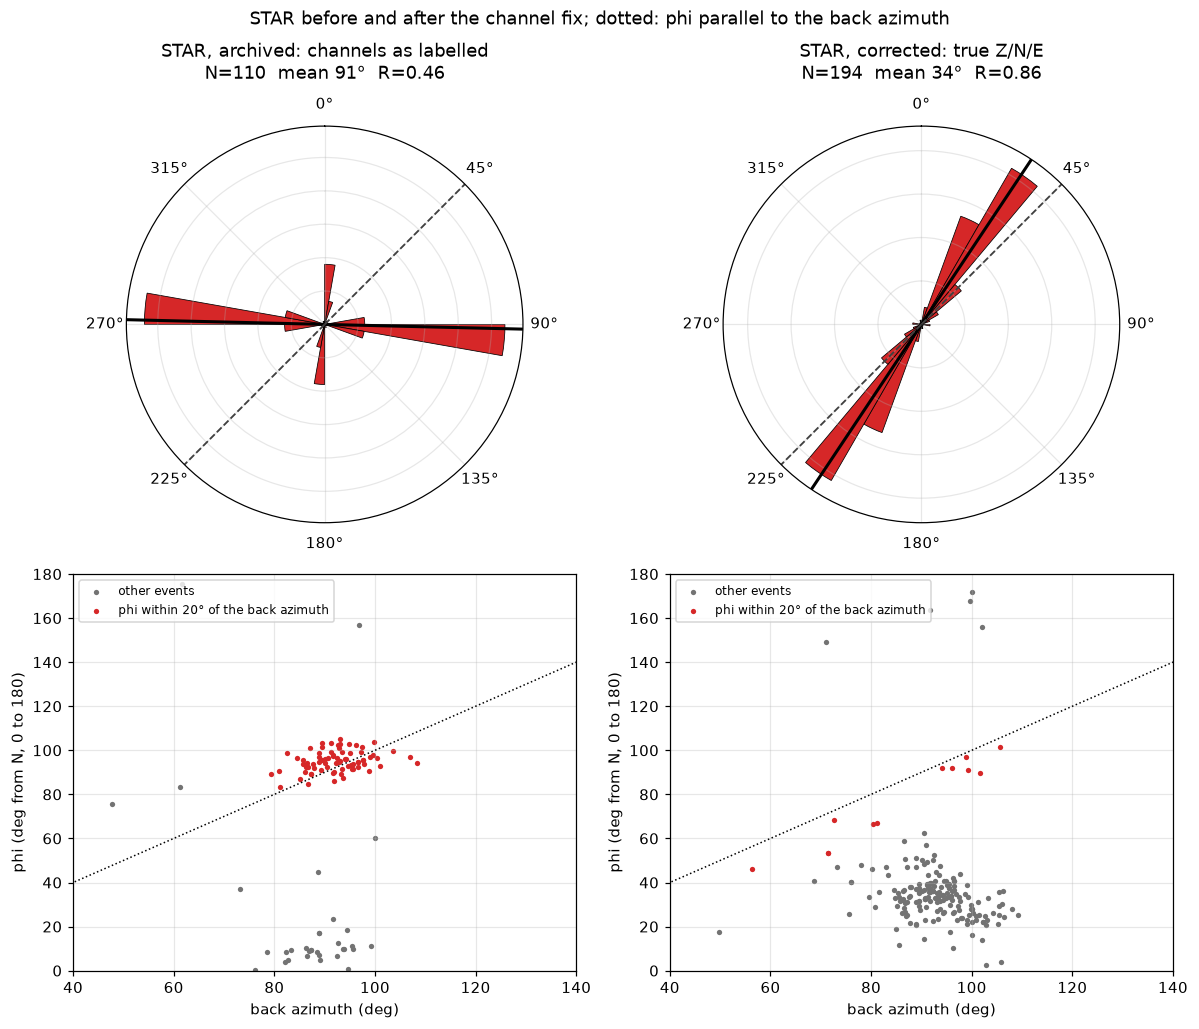

In [10]:
NEAR_DEG = 20             # half-width of the "near an axis" band, deg (the convention of notebooks 05 and 07)
archived = pd.read_csv(paths.station_results_csv("STAR"))       # computed on the channels as labelled
fig = plt.figure(figsize=(11, 9.5))
filtered_sets = []
for i, (name, r) in enumerate([("archived: channels as labelled", archived), ("corrected: true Z/N/E", res["STAR"])]):
    kept = quality.post_filtered(r)
    filtered_sets.append(set(kept.evid))
    m, R = stats.axial_mean(kept.phi)
    near = stats.near_axis(kept.phi, kept.back_azimuth, NEAR_DEG, perpendicular=False)
    rose(fig.add_subplot(2, 2, i + 1, projection="polar"), kept.phi, title=f"STAR, {name}\nN={len(kept)}  mean {m:.0f}°  R={R:.2f}")
    ax = fig.add_subplot(2, 2, i + 3)
    ax.scatter(kept.back_azimuth[~near], measure.phi_0_180(kept.phi[~near]), s=12, color="0.45", lw=0, label="other events")
    ax.scatter(kept.back_azimuth[near], measure.phi_0_180(kept.phi[near]), s=12, color="tab:red", lw=0,
               label=f"phi within {NEAR_DEG}° of the back azimuth")
    ax.plot([30, 150], [30, 150], "k:", lw=1)                    # phi along the ray
    ax.set(xlim=(40, 140), ylim=(0, 180), xlabel="back azimuth (deg)", ylabel="phi (deg from N, 0 to 180)")
    ax.legend(fontsize=8, loc="upper left")
    print(f"{name}: N = {len(kept)}, axial mean {m:.0f} deg (R {R:.2f}), median back azimuth {kept.back_azimuth.median():.0f} deg; "
          f"{near.sum()} ({near.mean():.0%}) within {NEAR_DEG} deg of the back azimuth "
          f"({stats.chance_near_axis(NEAR_DEG, perpendicular=False):.0%} expected by chance)")
print("events in both filtered sets:", len(filtered_sets[0] & filtered_sets[1]))
fig.suptitle("STAR before and after the channel fix; dotted: phi parallel to the back azimuth")
plt.tight_layout()

On the channels as labelled, the filtered fast directions (N = 110) cluster east-west, around 91 degrees, right on the median back azimuth of 92: 77 of them (70 percent) lie within 20 degrees of the back azimuth, where 22 percent would by chance. That is the signature of a component error, and it was one (the README's *Known facts*). On the corrected channels the same check flags 12 of 194 (6 percent), below chance, and the fast directions cluster north-north-east instead. Only 44 events are in both filtered sets, so the correction did not just rotate the old answers: it changed which measurements pass.

Now the three stations with the most measurements, coloured by Q_w:

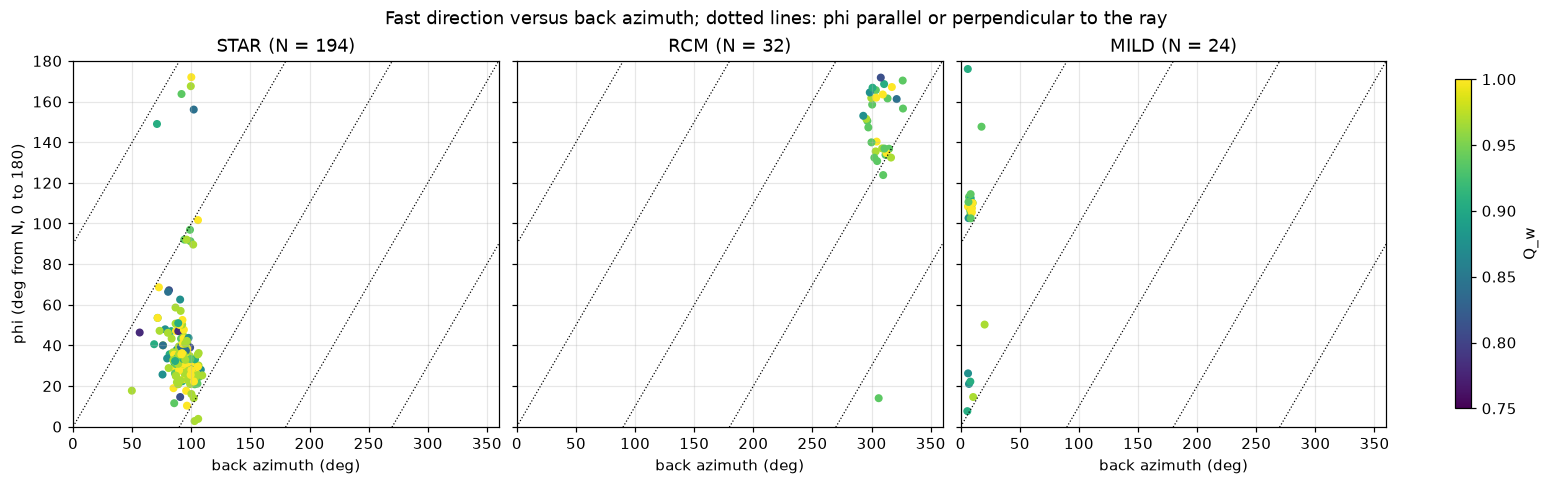

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True, layout="constrained")
for ax, s in zip(axes, ["STAR", "RCM", "MILD"]):
    kept = quality.post_filtered(res[s])
    pts = ax.scatter(kept.back_azimuth, measure.phi_0_180(kept.phi), c=kept.quality, cmap="viridis",
                     vmin=quality.DEFAULT_POST.qw_min, vmax=1, s=18)
    for off in (-270, -180, -90, 0, 90, 180):      # every fold of 'parallel' and 'perpendicular'
        ax.plot([0, 360], [off, off + 360], "k:", lw=0.8)
    ax.set(xlabel="back azimuth (deg)", title=f"{s} (N = {len(kept)})", ylim=(0, 180), xlim=(0, 360))
axes[0].set_ylabel("phi (deg from N, 0 to 180)")
fig.colorbar(pts, ax=axes, label="Q_w", shrink=0.9)
fig.suptitle("Fast direction versus back azimuth; dotted lines: phi parallel or perpendicular to the ray");

At STAR almost all rays come from one back azimuth (about 90 degrees, east), so this plot cannot show whether phi would change for waves arriving from other directions; what it shows is that the corrected fast directions do not follow the back azimuth (they sit about 60 degrees from it). RCM's rays come from the north-west (back azimuths around 307) and MILD's from the north (around 8), each again from a narrow range, because the swarm is small and sits under the summit. So each station sees the swarm through one window, and a station-to-station difference is also a difference in back azimuth. Testing direction dependence properly needs earthquakes in other places, or many more stations around the same earthquakes: the nodal array of the README.

## 8. Percent anisotropy

Section 4 defined percent anisotropy, 100 × dt / travel time, and what it assumes. The left panel puts every filtered measurement on a plot of dt against travel time: lines of constant percent anisotropy run through the origin. Points along one such line would mean anisotropy spread evenly along the paths; the same dt at every travel time would mean a shallow layer under each station. The right panel gives each station's value in the form the series uses for percent anisotropy everywhere (notebooks 06 and 07): the **mean with a 68 percent bootstrap interval, with the median alongside**.

The **bootstrap** (Efron and Tibshirani, 1993; `stats.bootstrap`) estimates how much a statistic would change with another sample of the same size: draw N values at random from the N you have, with replacement (so some appear twice and some not at all), recompute the statistic, repeat 1,000 times. The middle 68 percent of those values is the **68 percent interval**, the counterpart of ± 1 standard error. It treats the events as independent, which they are not quite (events close in time are alike), so it is a lower bound on the uncertainty; notebook 07 shows how much wider it gets when whole days are resampled instead. The grey bars show what one step of dt (0.02 s, or 0.04 s at MILD; exercise 4) is worth at each station's typical travel time.

STAR's dt step 0.02 s = measure.dt_step(100 Hz) = 0.02 s
           N  mean %  68% low  68% high  median %  dt step (s)  median travel time (s)  one step (% points)
station                                                                                                    
STAR     194    2.93     2.85      3.01      3.25         0.02                    1.81                 1.10
RCM       32    3.40     3.19      3.59      3.59         0.02                    1.62                 1.23
MILD      24    2.19     2.09      2.32      1.99         0.04                    2.03                 1.97
LON       38    0.68     0.61      0.75      0.56         0.02                    3.67                 0.55


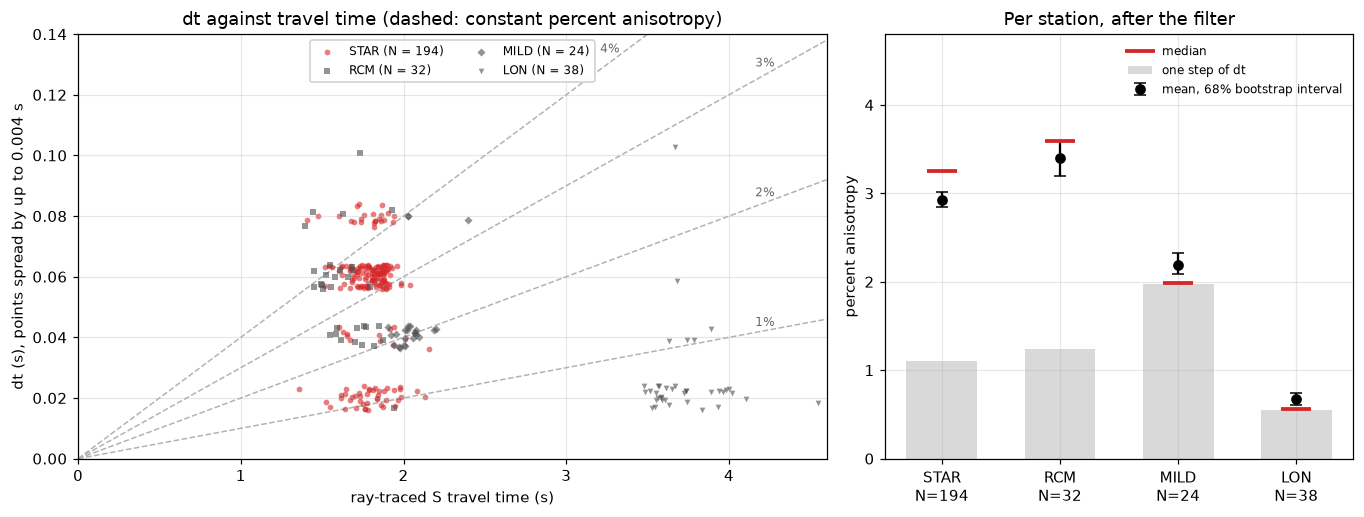

In [12]:
def dt_grid(r):
    """Spacing of the dt values in a station's successful measurements, s (measure.dt_step at its sampling rate)."""
    v = np.unique(np.round(quality.successful(r).dt, 4))
    return float(np.diff(v).min())

MEASURED = ["STAR", "RCM", "MILD", "LON"]                       # the stations with filtered measurements
rows = []
for s in MEASURED:
    kept = quality.post_filtered(res[s])
    a = kept.pct_anisotropy.to_numpy()
    mean, lo, hi, _ = stats.bootstrap(a, np.mean)              # 1,000 resamples, 68 percent interval
    rows.append({"station": s, "N": len(a), "mean %": mean, "68% low": lo, "68% high": hi, "median %": np.median(a),
                 "dt step (s)": dt_grid(res[s]), "median travel time (s)": kept.travel_time_s.median()})
aniso = pd.DataFrame(rows).set_index("station")
aniso["one step (% points)"] = 100 * aniso["dt step (s)"] / aniso["median travel time (s)"]
print(f"STAR's dt step {dt_grid(res['STAR']):.2f} s = measure.dt_step(100 Hz) = {measure.dt_step(100.0):.2f} s")
print(aniso.round(2).to_string())

look = {"STAR": dict(color="tab:red", marker="o"), "RCM": dict(color="0.3", marker="s"),
        "MILD": dict(color="0.3", marker="D"), "LON": dict(color="0.3", marker="v")}
rng = np.random.default_rng(0)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
T_MAX, DT_MAX = 4.6, 0.14                                      # plot limits
for p in (1, 2, 3, 4):
    t_end = min(T_MAX * 0.93, DT_MAX * 0.95 / (p / 100))          # where the line leaves the plot
    ax0.plot([0, T_MAX], [0, p / 100 * T_MAX], color="0.7", lw=1, ls="--", zorder=0)
    ax0.text(t_end, p / 100 * t_end, f"{p}%", ha="right", va="bottom", fontsize=8, color="0.4")
for s in MEASURED:
    kept = quality.post_filtered(res[s])
    ax0.scatter(kept.travel_time_s, kept.dt + rng.uniform(-0.004, 0.004, len(kept)), s=14, alpha=0.6, lw=0,
                label=f"{s} (N = {len(kept)})", **look[s])
ax0.legend(fontsize=8, loc="upper center", ncol=2, framealpha=0.95)
ax0.set(xlim=(0, T_MAX), ylim=(0, DT_MAX), xlabel="ray-traced S travel time (s)", ylabel="dt (s), points spread by up to 0.004 s",
        title="dt against travel time (dashed: constant percent anisotropy)")
x = np.arange(len(aniso))
ax1.bar(x, aniso["one step (% points)"], color="0.85", width=0.6, label="one step of dt")
ax1.errorbar(x, aniso["mean %"], yerr=[aniso["mean %"] - aniso["68% low"], aniso["68% high"] - aniso["mean %"]],
             fmt="o", color="k", capsize=4, label="mean, 68% bootstrap interval")
ax1.plot(x, aniso["median %"], "_", color="tab:red", ms=20, mew=2.5, label="median")
ax1.set(xticks=x, xticklabels=[f"{s}\nN={n}" for s, n in zip(aniso.index, aniso.N)], ylim=(0, 4.8),
        ylabel="percent anisotropy", title="Per station, after the filter")
ax1.legend(fontsize=8, frameon=False, loc="upper right")
plt.tight_layout()

What the figure says:

- **The summit stations are at about 3 percent, MILD at about 2, LON below 1.** STAR's mean is 2.93 percent (68 percent interval 2.85 to 3.01, N = 194), RCM's 3.40 (3.19 to 3.59, N = 32), MILD's 2.19 (2.09 to 2.32, N = 24) and LON's 0.68 (0.61 to 0.75, N = 38).
- **Each value is one to three steps of dt.** One step is worth 1.10 percentage points at STAR, 1.23 at RCM, 1.97 at MILD and 0.55 at LON, and the delays come in steps, so the dots in the left panel sit in rows.
- **Why the median hardly moves.** 116 of STAR's 194 delays are 0.06 s, so its median is nearly always 0.06 s over a typical travel time, 3.25 percent, whichever events the bootstrap draws. The mean (2.93) is lower because the 43 events at 0.02 s pull it down. Report the mean with its interval, and the median alongside to show the steps.
- **The plot cannot tell path-averaged from shallow anisotropy.** Half of STAR's travel times lie between 1.7 and 1.9 s, across which path-averaged anisotropy of 3 percent would change dt by about 0.005 s, a quarter of a step. Across stations, LON's long paths (3.7 s) come with dt of one step, which fits a shallow layer, but LON's events were also filtered in higher bands, which give one-step delays at STAR too (section 9). Exercise 4 takes the numbers apart.

## 9. Time: does anything change during the swarm?

The scientific question is whether the anisotropy changed as fluids moved. Plot STAR's filtered phi and dt against origin time, with a **running mean** (the mean of each run of 15 consecutive events, axial for phi). But first remember what notebook 03 found (exercise 3): the filter bank chooses a band for each event, the share of events choosing 1-5 Hz changed during the swarm, and dt depends strongly on the band. So the points are coloured by band, there is a second running mean for the 1-5 Hz events alone, and the bottom panel shows the **band mix**, the share of filtered events at 1-5 Hz in each of notebook 03's five periods (UTC days).

period     Jul 8  Jul 9-10  Jul 11-14  Jul 15-21  Jul 22 on
N          28.00     59.00      50.00      45.00      12.00
share_1_5   0.29      0.73       0.74       0.87       0.75


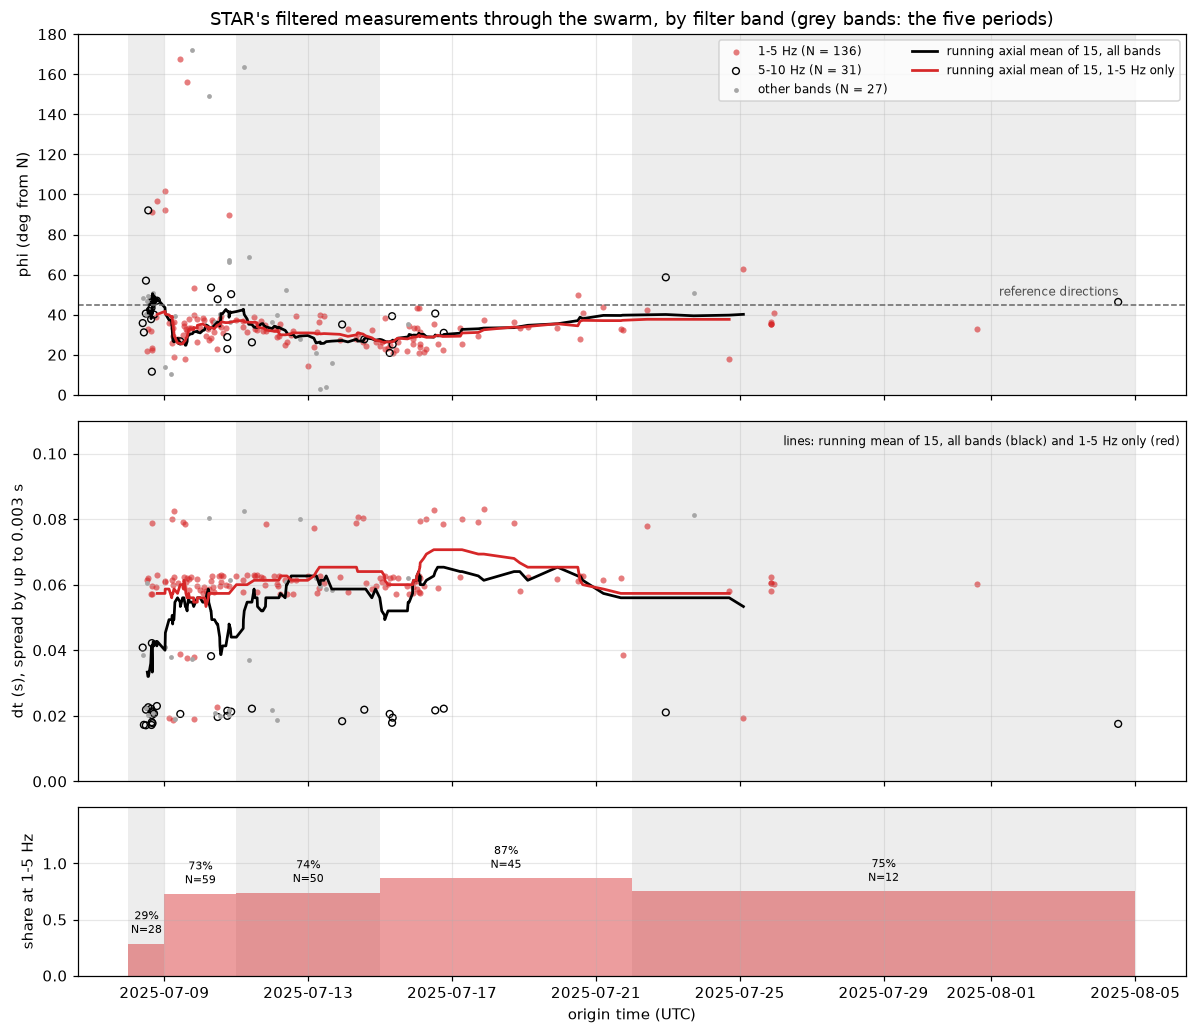

In [13]:
def rolling_axial_mean(phi_deg, n):
    """Axial mean of each run of n consecutive values (phi and phi + 180 are the same axis)."""
    two = np.deg2rad(2 * np.asarray(phi_deg, dtype=float))
    c, s = pd.Series(np.cos(two)).rolling(n, center=True).mean(), pd.Series(np.sin(two)).rolling(n, center=True).mean()
    return np.mod(np.rad2deg(np.arctan2(s, c)) / 2, 180)

N_RUN = 15                                                      # events in each running mean
PERIODS = ["Jul 8", "Jul 9-10", "Jul 11-14", "Jul 15-21", "Jul 22 on"]      # as in notebook 03, exercise 3 (UTC days)
STARTS = pd.to_datetime(["2025-07-08", "2025-07-09", "2025-07-11", "2025-07-15", "2025-07-22"], utc=True).as_unit("ns")
swarm = quality.post_filtered(res["STAR"]).copy()               # STAR's filtered measurements, in time order
swarm["time"] = pd.to_datetime(swarm.datetime, utc=True, format="ISO8601")
swarm = swarm.sort_values("time").reset_index(drop=True)
swarm["band"] = np.select([swarm.filter_band == "(1.0, 5.0)", swarm.filter_band == "(5.0, 10.0)"], ["1-5 Hz", "5-10 Hz"], "other bands")
swarm["period"] = pd.Categorical(np.array(PERIODS)[STARTS.searchsorted(swarm.time, side="right") - 1], PERIODS)
swarm_low = swarm[swarm.band == "1-5 Hz"]

look = {"1-5 Hz": dict(s=16, color="tab:red", alpha=0.6, lw=0),
        "5-10 Hz": dict(s=20, facecolors="none", edgecolors="k", lw=0.9),
        "other bands": dict(s=10, color="0.65", lw=0)}
fig, axes = plt.subplots(3, 1, figsize=(11, 9.5), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.4]})
spread = np.random.default_rng(0).uniform(-0.003, 0.003, len(swarm))
for b, kw in look.items():
    sel = swarm.band == b
    axes[0].scatter(swarm.time[sel], measure.phi_0_180(swarm.phi[sel]), label=f"{b} (N = {sel.sum()})", **kw)
    axes[1].scatter(swarm.time[sel], swarm.dt[sel] + spread[sel], **kw)
axes[0].plot(swarm.time, rolling_axial_mean(swarm.phi, N_RUN), color="k", lw=1.8, label=f"running axial mean of {N_RUN}, all bands")
axes[0].plot(swarm_low.time, rolling_axial_mean(swarm_low.phi, N_RUN), color="tab:red", lw=1.8, label=f"running axial mean of {N_RUN}, 1-5 Hz only")
axes[0].axhline(reference.REGIONAL_COMPRESSION_AZ, color="0.4", ls="--", lw=1)
axes[0].text(swarm.time.iloc[-1], reference.REGIONAL_COMPRESSION_AZ + 3, "reference directions", ha="right", va="bottom", fontsize=8, color="0.3")
axes[1].plot(swarm.time, swarm.dt.rolling(N_RUN, center=True).mean(), color="k", lw=1.8)
axes[1].plot(swarm_low.time, swarm_low.dt.rolling(N_RUN, center=True).mean(), color="tab:red", lw=1.8)
share = swarm.groupby("period", observed=True).agg(N=("band", "size"), share_1_5=("band", lambda b: (b == "1-5 Hz").mean()))
ends = list(STARTS[1:]) + [swarm.time.max().ceil("D")]
for (p, r), t0, t1, ax_i in zip(share.iterrows(), STARTS, ends, range(5)):
    axes[2].fill_between([t0, t1], [r.share_1_5] * 2, color="tab:red", alpha=0.45, lw=0)
    axes[2].text(t0 + (t1 - t0) / 2, r.share_1_5 + 0.06, f"{r.share_1_5:.0%}\nN={int(r.N)}", ha="center", va="bottom", fontsize=7.5)
    if ax_i % 2 == 0:
        for ax in axes:
            ax.axvspan(t0, t1, color="0.93", zorder=0, lw=0)
axes[0].set(ylabel="phi (deg from N)", ylim=(0, 180), title="STAR's filtered measurements through the swarm, by filter band (grey bands: the five periods)")
axes[0].legend(fontsize=8, ncol=2, loc="upper right")
axes[1].set(ylabel="dt (s), spread by up to 0.003 s", ylim=(0, 0.11))
axes[1].text(0.995, 0.96, "lines: running mean of 15, all bands (black) and 1-5 Hz only (red)", transform=axes[1].transAxes, ha="right", va="top", fontsize=8)
axes[2].set(ylabel="share at 1-5 Hz", ylim=(0, 1.5), yticks=[0, 0.5, 1], xlabel="origin time (UTC)")
plt.tight_layout()
print(share.T.round(2).to_string())

Read the dt panel first. The all-band running mean (black) rises from 0.03 to 0.04 s on 8 July to about 0.06 s by 12 July and stays there. That looks like a change in the rock, but the colours say otherwise: on 8 July most filtered events were filtered at 5-10 Hz (open circles), whose delays are almost all 0.02 s, and only 29 percent at 1-5 Hz (red), whose delays are mostly 0.06 s. From 9 July the share at 1-5 Hz is 73 to 87 percent. The 1-5 Hz running mean (red line) stays between 0.053 and 0.071 s from the first day to the last, 0.057 s on 8 July: no rise at the start. So the rise of the pooled dt is a change in the **band mix**, not in the delays within a band; exercise 5 puts numbers on it.

The phi panel is less clear. The all-band running mean starts between 38 and 50 degrees on 8 July, swings between 25 and 43 on 9 to 11 July, settles at 26 to 34 from 12 to 18 July, and climbs back to about 40 among the sparse later events, close to the reference directions. Part of the early high value is again the band (the 5-10 Hz events lean a few degrees further east than the 1-5 Hz ones; exercises 5 and 7), and the red line starts high on only a handful of 1-5 Hz events. Whether the change of a few degrees between early and later events is larger than chance is a question of the uncertainty of each period's mean, and events on the same day are not independent. **That test is notebook 07's** (a permutation test within one band, and intervals that resample whole days). Here, note what a fair test has to compare: like with like, one band at a time.

## 10. Glossary

| term | meaning | section |
| --- | --- | --- |
| 68 percent interval | the middle 68 percent of the bootstrap values; the counterpart of ± 1 standard error | 8 |
| anisotropic | wave speed depends on the direction the wave travels or shakes in | 4 |
| archived results | Michael's original results files; STAR's was computed on the exchanged channels | note, 7 |
| artifact check | does phi follow the back azimuth? A component error or a ray-path effect would make it | 7 |
| axial mean | the mean of axes: double the angles, average the unit vectors, halve the direction | 5 |
| back azimuth | the direction from the station towards the earthquake, clockwise from north | 1 |
| band mix | the share of events for which the filter bank chose each band | 9 |
| bootstrap | resample the N values with replacement many times and recompute; the spread is the sampling uncertainty | 8 |
| circular standard deviation | the spread of single axes around their mean, √(−2 ln R) / 2 in degrees | 5 |
| clipped | a wave larger than the digitizer's largest count, recorded cut flat | note |
| crack | a thin gap in rock, usually fluid-filled; soft to shear across, stiff along | 4 |
| critical angle | sin⁻¹(Vs/Vp), about 35 degrees: the edge of the shear-wave window | 4 |
| dike | a sheet of once-molten rock cutting through older rock | 4 |
| epicentral distance | the distance along the surface from the epicentre (the point above the earthquake) to the station | exercise 3 |
| formal errors | phi_error and dt_error: half-widths of SWSPy's 99.7 percent confidence region | 1, 3 |
| free surface | the ground surface, where an arriving wave reflects | exercise 3 |
| Jurkevics angle | the P wave's angle from vertical, from the eigenvalues of its particle motion (Jurkevics, 1988) | 1 |
| maximum horizontal compressive stress (SHmax) | the horizontal direction in which the rock is squeezed hardest | 4 |
| mean resultant length R | the length of the average unit vector: 1 for identical axes, 0 for no preferred axis | 5 |
| null | a wave that arrives shaking along the fast or slow direction and so does not split | 4 |
| particle motion | the path the ground traces in three dimensions as a wave passes | 1 |
| path-averaged | one value for the whole ray, with no information about where along it | 4 |
| percent anisotropy | 100 × dt / travel time: about how much faster the fast S wave is than the slow one, in percent | 4, 8 |
| post-processing filter | the five cuts that decide which successful measurements to trust (`quality.PostFilter`) | 2 |
| pre-processing gates | the checks that decide whether a measurement is attempted (`quality.PreGates`) | 2 |
| p-value | the probability of a result at least this extreme if there were no effect | 5 |
| Q_w | quality from -1 (a null) through 0 (the two methods disagree) to +1 (a good split) | 1, 3 |
| radial direction | the direction from the summit to a station | exercise 6 |
| ray-path effect | anything about the path rather than the rock under the station that changes a measurement | 7 |
| ray tracing | computing the path and travel time of a wave through a velocity model | 1 |
| Rayleigh test | is R larger than random axes would give? | 5 |
| rectilinearity | how line-like the P wave's particle motion is, 0 to 1 | 1 |
| reference directions | the regional SHmax and the strike of the 2009 structure, both about NE (`rainier_sws.reference`) | 4 |
| rose diagram | a histogram of axes on a circle, mirrored | 5 |
| running mean | the mean of each run of N consecutive events | 9 |
| shear-wave window | rays steep enough (within about 35 degrees of vertical) that the free surface does not distort S | 4 |
| source polarization | the direction the S wave first shakes in, set by the focal mechanism | 4 |
| stage | where an event stopped in the pipeline | 1, 2 |
| standard error (SE) | the standard deviation of a mean, s / √N | exercise 5 |
| strike | the direction of the line a fault, dike or layer makes with a horizontal surface | 4 |
| stress-aligned anisotropy | cracks held open parallel to SHmax, so phi parallel to SHmax | 4 |
| structural anisotropy | phi parallel to the strike of faults, dikes or layering, whatever the stress | 4 |
| velocity model | a three-dimensional map of seismic wave speed | 1 |
| Z/N/E | vertical, north and east components | note |

References in this notebook: Boness, N.L. & Zoback, M.D. (2006), *Mapping stress and structurally controlled crustal shear velocity anisotropy in California*, Geology 34, 825-828. Crampin, S. & Peacock, S. (2008), *A review of the current understanding of seismic shear-wave splitting in the Earth's crust and common fallacies in interpretation*, Wave Motion 45, 675-722. Efron, B. & Tibshirani, R.J. (1993), *An Introduction to the Bootstrap*, Chapman & Hall. Fisher, N.I. (1993), *Statistical Analysis of Circular Data*, Cambridge University Press. Gerst, A. & Savage, M.K. (2004), *Seismic anisotropy beneath Ruapehu volcano: a possible eruption forecasting tool*, Science 306, 1543-1547. Jurkevics, A. (1988), *Polarization analysis of three-component array data*, BSSA 78, 1725-1743. Shelly, D.R., Moran, S.C. & Thelen, W.A. (2013), *Evidence for fluid-triggered slip in the 2009 Mount Rainier, Washington earthquake swarm*, GRL 40, 1506-1512. Svenningsen, L. & Jacobsen, B.H. (2007), *Absolute S-velocity estimation from receiver functions*, GJI 170, 1089-1094. Wüstefeld, A., Al-Harrasi, O., Verdon, J.P., Wookey, J. & Kendall, J.-M. (2010), *A strategy for automatic shear-wave splitting analysis and quality control*, Geophys. Prospect. 58, 755-773.

## 11. Exercises

Each one asks a question the project needs answered, with the tools of this lesson. Exercises 3 and 7 are optional stretch exercises.

1. **Does the filter choose the direction?** The post-processing filter keeps 194 of STAR's 659 successful measurements, and the kept ones cluster north-north-east. Make `hist_panel` for RCM and MILD, and for STAR, RCM and MILD count how many successful measurements fail each of the five cuts, and how many fail *only* that cut. Then the question that matters: draw STAR's rose for the kept measurements, for those rejected only by Q_w, and for those rejected only by phi_error. If the filter had manufactured the north-north-east cluster, by keeping only one kind of answer, the rejected measurements would point somewhere else. Do they?
2. **LON, the far station.** Add LON to the rose figure of section 5. Where is LON relative to the swarm (epicentral distance, travel time, ray-traced incidence angle)? Its measurements were made with the Jurkevics angle in place of the ray-traced one; why? How does its fast direction compare with the reference directions, and with its back azimuth? Would you put LON on the same footing as STAR?
3. (Stretch) **Which stations are inside the shear-wave window?** For every station, plot the ray-traced incidence angle and the Jurkevics angle against **epicentral distance** (along the surface, from the epicentre, the point above the earthquake, to the station), with the critical angle and the gate marked. Geometry says the angle must grow with distance; does each estimate? Where do the two disagree, and by how much? Can the **free surface** explain it? (At the free surface the P wave's particle motion is the sum of the arriving P wave and the P and S waves it reflects, so the apparent angle is not the ray's: for uniform rock, sin(apparent / 2) = sin(ray angle) × Vs / Vp; Svenningsen and Jacobsen, 2007.) Leave changing the 45-degree cutoff to notebook 07.
4. **What is a station's percent anisotropy made of?** Section 8 ranked the stations. For each one, find the step of its dt values (`measure.dt_step`, and the sampling rate it implies) and how many steps its median delay is; compare STAR's 1-5 Hz and 5-10 Hz events; and compare `travel_time_s`, which comes from the velocity model, with the observed S travel time (the S pick minus the origin time, both in `paths.STRICT_CATALOG_CSV`). Which station is the most anisotropic, and do you believe it?
5. **Is the rise of dt during the swarm a band artifact?** Section 9 suggested so. Put numbers on it: for each of the five periods compute the pooled mean dt with its **standard error** (SE, the standard deviation of a mean: s / √N), the share of 1-5 Hz events, and the mean dt of the 1-5 Hz events alone. Then predict each period's pooled mean from its band mix alone, using each band's mean dt over the whole swarm. Does the prediction follow the measurement? Make the same comparison for phi.
6. **Stress or structure?** For STAR, RCM, MILD and LON compute the axial mean with its 68 percent bootstrap interval (`stats.bootstrap_axial_mean`), R and N, and the angle between the mean and each reference direction (`stats.axial_diff`). At which stations does the azimuth tell the two hypotheses apart? Which observations from this notebook could, and what would each hypothesis predict for them? One more check: the swarm is under the summit, so compare each mean with the **radial direction**, from the summit to the station. A stress field bent by the edifice might line cracks up radially or around the summit; what else lies along the radial direction here?
7. (Stretch) **Does phi depend on back azimuth?** STAR's rays all come from the east, but their back azimuths still span about 60 degrees. Fit a straight line to phi (measured from the axial mean, so the jump between 0 and 180 does not matter) against back azimuth for all filtered events, then for the 1-5 Hz and 5-10 Hz events separately, with 68 percent bootstrap intervals on the slopes. Is there a dependence, and where does it come from?

Next: `07_uncertainty_and_thresholds.ipynb`, where these descriptions get error bars and tests.

## 12. Example solutions

One way to do each exercise. Try them yourself first. STAR's rows are the corrected re-run (the note at the top); the other stations' channels point where their names say.

### Exercise 1: does the filter choose the direction?

The histograms show where the cuts fall; to say which one *removes the most*, count, among the successful measurements, how many fail each cut. A measurement can fail several cuts at once, so also count the ones that fail **only** that cut: those are the events that cut alone is responsible for.

STAR: 659 successful, 194 pass the filter; 206 of the 465 rejected fail exactly one cut
                  fail this cut  fail only this cut
SNR < 2.0                     0                   0
Q_w < 0.75                  309                  72
dt_error > 0.05             100                   0
phi_error > 20.0            333                 106
dt > half period            109                  28 

RCM: 274 successful, 32 pass the filter; 102 of the 242 rejected fail exactly one cut
                  fail this cut  fail only this cut
SNR < 2.0                     0                   0
Q_w < 0.75                  191                  60
dt_error > 0.05              59                   1
phi_error > 20.0            147                  33
dt > half period             67                   8 

MILD: 107 successful, 24 pass the filter; 22 of the 83 rejected fail exactly one cut
                  fail this cut  fail only this cut
SNR < 2.0                     0                   0
Q_w < 0.7

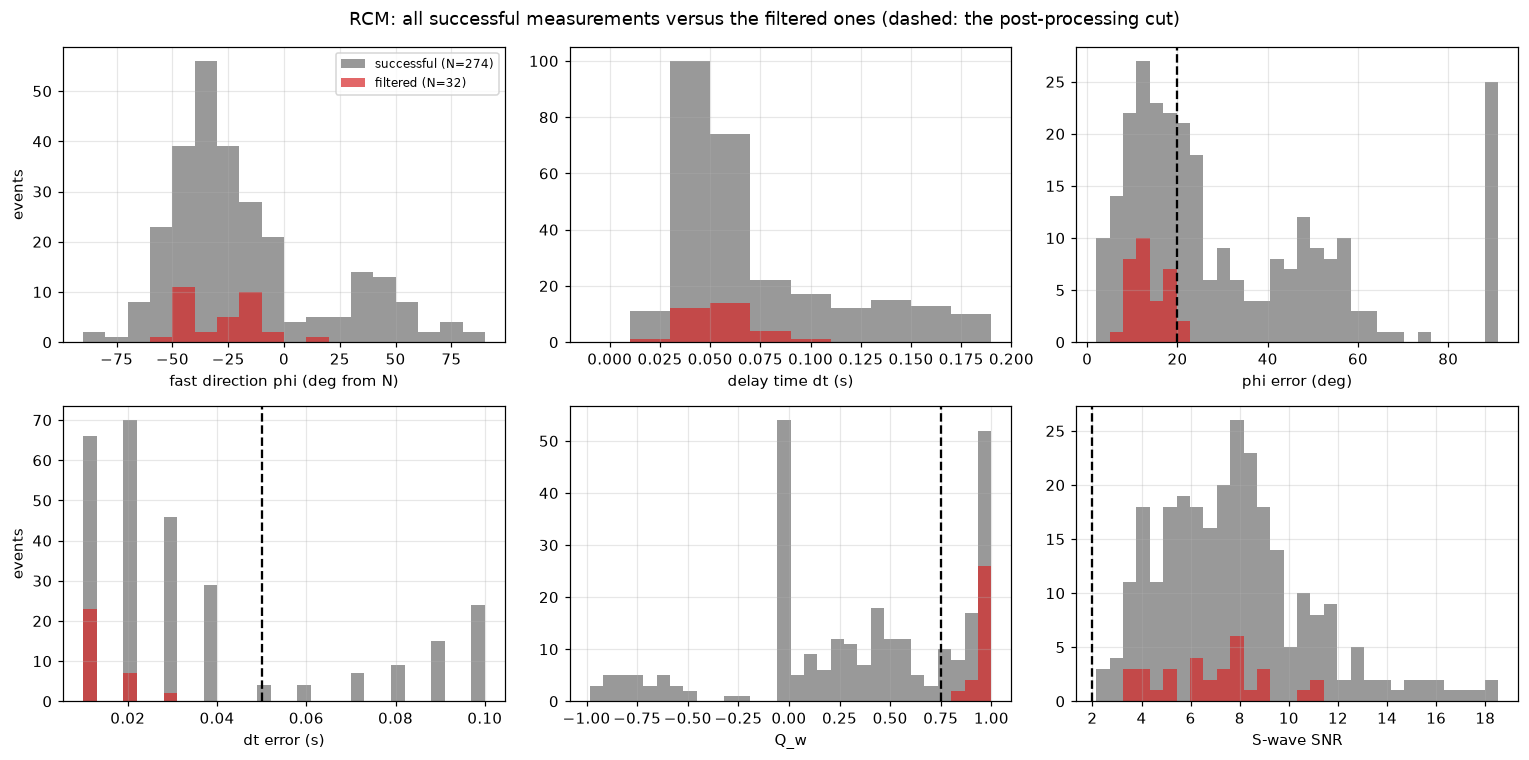

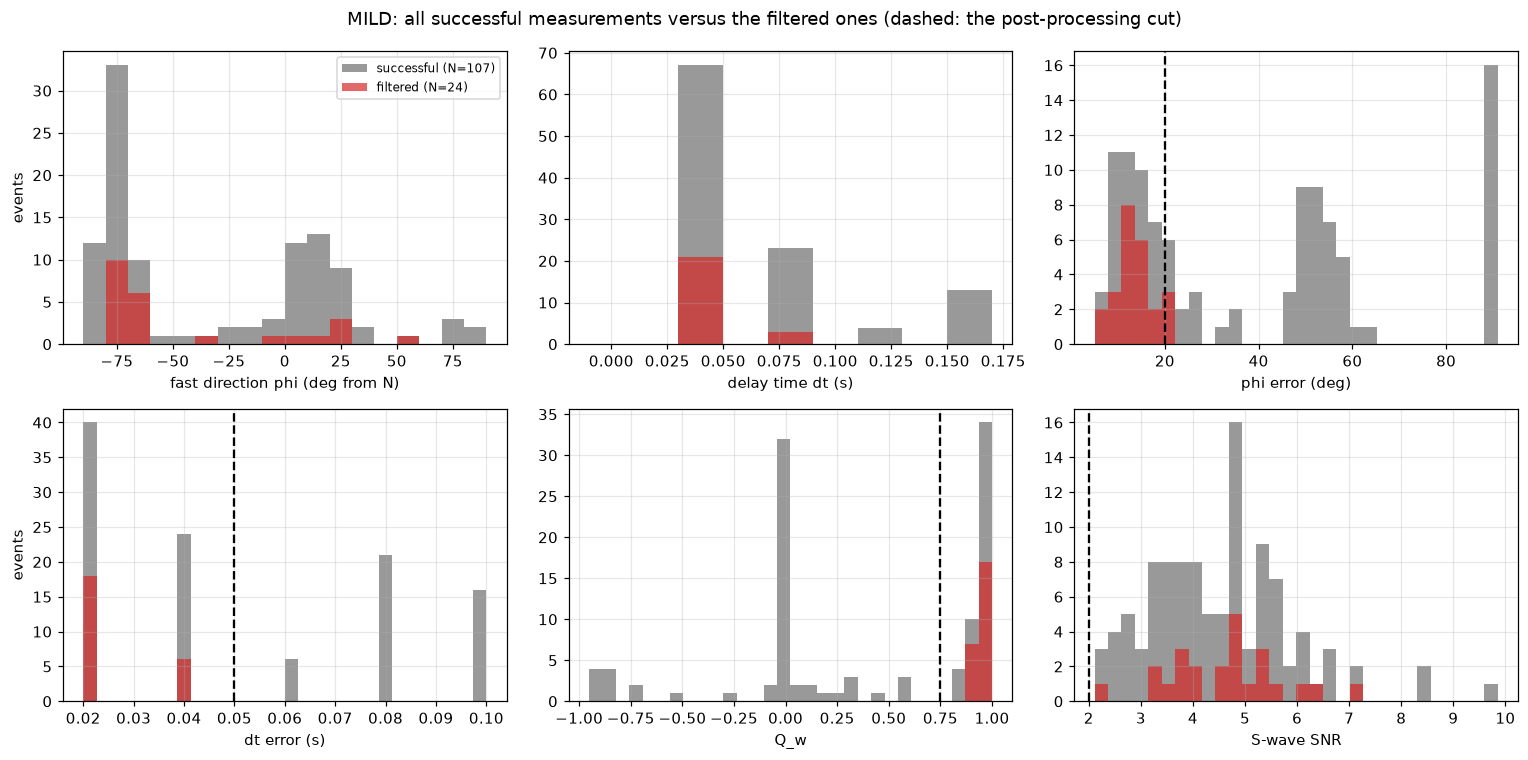

In [14]:
hist_panel(res["RCM"], "RCM: all successful measurements versus the filtered ones")
hist_panel(res["MILD"], "MILD: all successful measurements versus the filtered ones")

g = quality.DEFAULT_POST
def cut_failures(r):
    """One column per post-processing cut: True where a successful measurement fails it."""
    ok = quality.successful(r)
    return pd.DataFrame({
        f"SNR < {g.snr_min}": ok.snr_horizontal < g.snr_min,
        f"Q_w < {g.qw_min}": ok.quality < g.qw_min,
        f"dt_error > {g.dt_error_max}": ok.dt_error > g.dt_error_max,
        f"phi_error > {g.phi_error_max}": ok.phi_error > g.phi_error_max,
        "dt > half period": ok.dt > ok.dominant_period * g.dt_period_fraction,
    })

for s in ["STAR", "RCM", "MILD"]:
    fails = cut_failures(res[s])
    only = fails[fails.sum(axis=1) == 1]
    f = quality.funnel(res[s])
    print(f"{s}: {f.successful} successful, {f.filtered} pass the filter; {(fails.sum(axis=1) == 1).sum()} of the "
          f"{f.successful - f.filtered} rejected fail exactly one cut")
    print(pd.DataFrame({"fail this cut": fails.sum(), "fail only this cut": only.sum()}).to_string(), "\n")

**Q_w and phi_error do almost all the work** at every station. At STAR, 333 of the 659 successful measurements have phi errors above 20 degrees and 309 have Q_w below 0.75; 106 and 72 fail on that cut alone, and the dt <= T/2 cut removes another 28 alone (notebook 03, exercise 4). At RCM the same two lead (191 and 147 of 274), and at MILD (59 and 61 of 107). The **SNR cut removes nothing** anywhere: the pre-processing gate already required an SNR of at least 2, so the post-processing SNR cut is redundant with the default thresholds. dt_error almost never matters on its own (at most one event per station), because a large dt error comes with a large phi error and a low Q_w.

The cuts overlap heavily: of STAR's 465 rejected measurements only 206 fail a single cut (RCM 102 of 242, MILD 22 of 83), so loosening any one threshold lets in far fewer events than its "fail this cut" count suggests. In the RCM and MILD histograms, note the spike of phi errors near 90 degrees (no constraint at all), the pile-up of Q_w at exactly 0, and MILD's delays in multiples of 0.04 s, where the others step by 0.02 s (exercise 4).

Now the direction of the rejected measurements:

kept by the filter          N = 194  axial mean  33.7 deg  R 0.86  share between 20 and 40 deg 70%
rejected only by Q_w        N =  72  axial mean  41.6 deg  R 0.49  share between 20 and 40 deg 43%
rejected only by phi_error  N = 106  axial mean  46.6 deg  R 0.52  share between 20 and 40 deg 29%
every rejected measurement  N = 465  axial mean  39.3 deg  R 0.43  share between 20 and 40 deg 33%


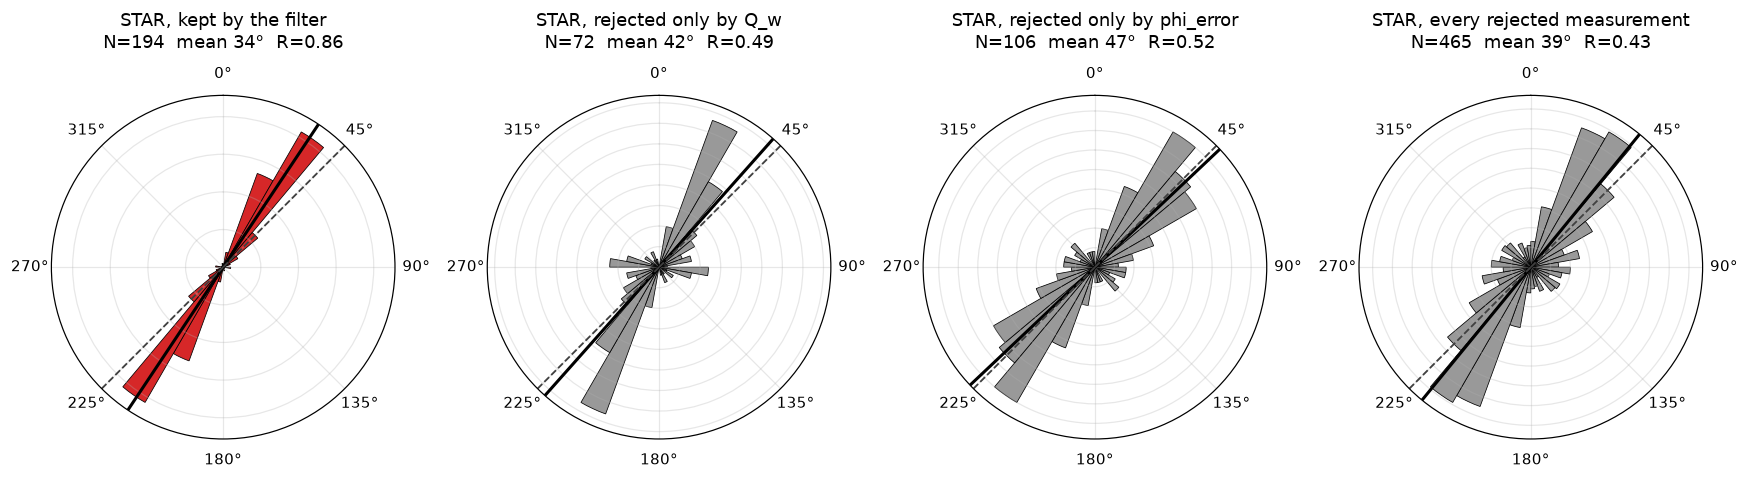

In [15]:
ok = quality.successful(res["STAR"])
fails = cut_failures(res["STAR"])
one_cut = fails.sum(axis=1) == 1
groups = {"kept by the filter": ok[~fails.any(axis=1)],
          "rejected only by Q_w": ok[one_cut & fails[f"Q_w < {g.qw_min}"]],
          "rejected only by phi_error": ok[one_cut & fails[f"phi_error > {g.phi_error_max}"]],
          "every rejected measurement": ok[fails.any(axis=1)]}
fig = plt.figure(figsize=(16, 4.8))
for i, (name, sub) in enumerate(groups.items()):
    m, R = stats.axial_mean(sub.phi)
    rose(fig.add_subplot(1, 4, i + 1, projection="polar"), sub.phi, color="tab:red" if i == 0 else "0.6",
         title=f"STAR, {name}\nN={len(sub)}  mean {m:.0f}°  R={R:.2f}")
    print(f"{name:27s} N = {len(sub):3d}  axial mean {m:5.1f} deg  R {R:.2f}  "
          f"share between 20 and 40 deg {((measure.phi_0_180(sub.phi) >= 20) & (measure.phi_0_180(sub.phi) <= 40)).mean():.0%}")
plt.tight_layout()

**No: the rejected measurements point the same way, only more loosely.** The 72 measurements rejected only by Q_w have an axial mean of 42 degrees (R = 0.49), the 106 rejected only by phi_error 47 degrees (R = 0.52), and all 465 rejected measurements together 39 degrees (R = 0.43), against 34 degrees (R = 0.86) for the 194 kept. The north-north-east direction is in the data before any cut; the filter sharpens it by removing the scattered measurements around it (70 percent of the kept ones lie between 20 and 40 degrees, a third of the rejected ones).

Two smaller points. The rejected means sit 6 to 13 degrees further east than the kept one, so the filter does move the mean a little; how much a threshold moves the answer, compared with its uncertainty, is notebook 07's threshold sweep. And a rejected measurement is not a wrong one: many fail on a phi_error that has hit its ceiling, which says the grid search could not pin phi down, not that phi is elsewhere.

### Exercise 2: LON, the far station

The same rose figure with LON as a fourth panel, then each station's geometry and its fast direction against the reference directions and the back azimuth. `with_geometry` (used again in exercises 3 and 4) adds the epicentral distance and the observed S travel time from the strict catalog.

STAR all 1196 events: epicentral distance  2.2 km, travel time 1.8 s, ray-traced incidence 16 to 74 deg, Jurkevics median 61 deg
     filtered N = 194: mean phi 34 deg, 11 deg from the references, 59 deg from the median back azimuth (93); Rayleigh p = 6.6e-61
RCM  all 509 events: epicentral distance  3.0 km, travel time 1.7 s, ray-traced incidence 17 to 87 deg, Jurkevics median 69 deg
     filtered N = 32: mean phi 151 deg, 74 deg from the references, 24 deg from the median back azimuth (307); Rayleigh p = 2.4e-10
MILD all 685 events: epicentral distance  4.7 km, travel time 2.0 s, ray-traced incidence 30 to 85 deg, Jurkevics median 28 deg
     filtered N = 24: mean phi 110 deg, 65 deg from the references, 78 deg from the median back azimuth (8); Rayleigh p = 1.3e-02
LON  all 1172 events: epicentral distance 11.6 km, travel time 3.7 s, ray-traced incidence 62 to 81 deg, Jurkevics median 36 deg
     filtered N = 38: mean phi 7 deg, 38 deg from the references, 9 deg from the median back 

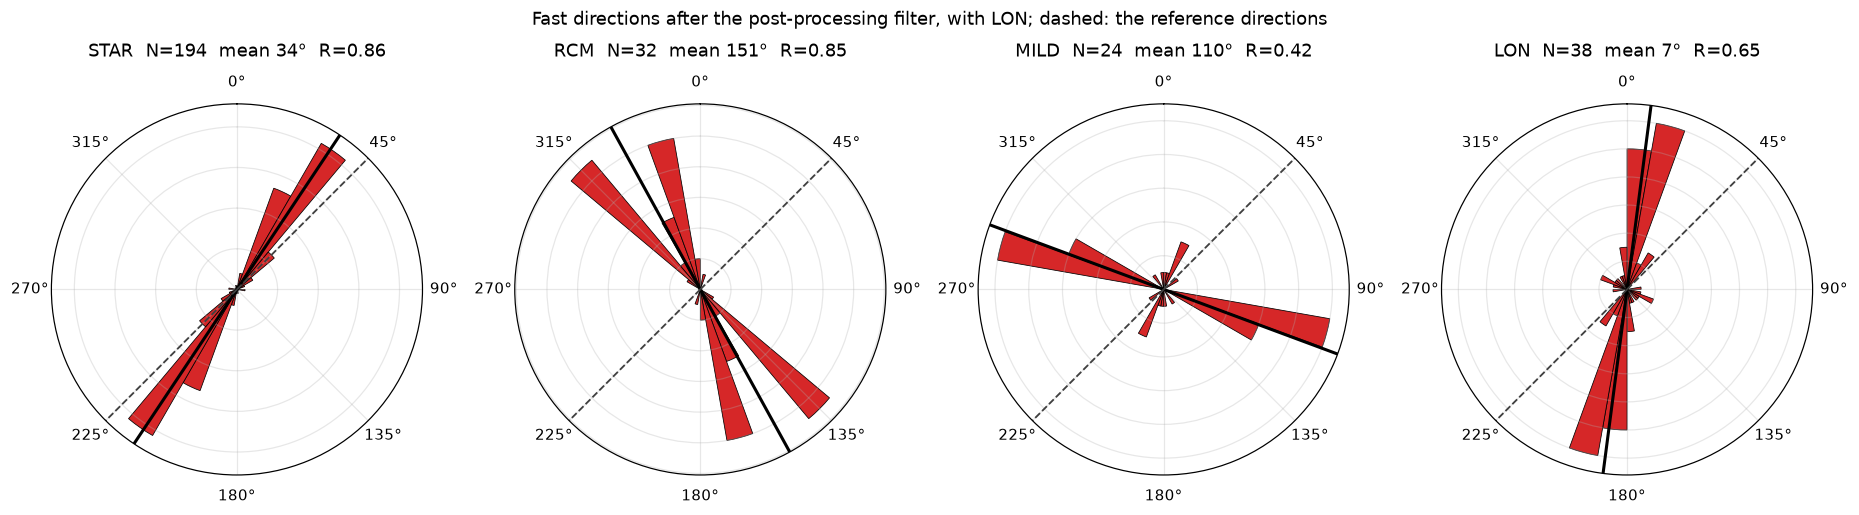

In [16]:
strict = pd.read_csv(paths.STRICT_CATALOG_CSV)                # every station's picks, with event locations
for c in data.TIME_COLUMNS:
    strict[c] = pd.to_datetime(strict[c], utc=True, format="ISO8601")

def with_geometry(r, s):
    """Add the epicentral distance (km) and the observed S travel time (S pick minus origin time, s) to a results table."""
    lat, lon, _ = data.station_coords(s)
    m = r.merge(strict[strict.station == s][["evid", "event_lat", "event_lon", "origin_time", "s_time"]], on="evid", how="left")
    m["epicentral_km"] = [gps2dist_azimuth(a, b, lat, lon)[0] / 1e3 for a, b in zip(m.event_lat, m.event_lon)]
    m["s_travel_obs"] = (m.s_time - m.origin_time).dt.total_seconds()
    return m

fig = plt.figure(figsize=(17, 4.8))
for i, s in enumerate(MEASURED):
    kept = quality.post_filtered(res[s])
    m, R = stats.axial_mean(kept.phi)
    rose(fig.add_subplot(1, 4, i + 1, projection="polar"), kept.phi, title=f"{s}  N={len(kept)}  mean {m:.0f}°  R={R:.2f}")
fig.suptitle("Fast directions after the post-processing filter, with LON; dashed: the reference directions")
plt.tight_layout()

for s in MEASURED:
    geo = with_geometry(res[s], s)
    kept = quality.post_filtered(geo)
    m, R = stats.axial_mean(kept.phi)
    print(f"{s:4s} all {len(geo)} events: epicentral distance {geo.epicentral_km.median():4.1f} km, travel time {geo.travel_time_s.median():.1f} s, "
          f"ray-traced incidence {geo.incidence_angle.min():.0f} to {geo.incidence_angle.max():.0f} deg, Jurkevics median {geo.incidence_angle_jurkevics.median():.0f} deg")
    print(f"     filtered N = {len(kept)}: mean phi {m:.0f} deg, {float(stats.axial_diff(m, reference.REGIONAL_COMPRESSION_AZ)):.0f} deg from the references, "
          f"{float(stats.axial_diff(m, kept.back_azimuth.median())):.0f} deg from the median back azimuth ({kept.back_azimuth.median():.0f}); "
          f"Rayleigh p = {stats.rayleigh_test(kept.phi)[1]:.1e}")

**LON's rose is tight but should not be read like the others.** Its fast directions cluster around 7 degrees, almost north-south (R = 0.65, N = 38), 38 degrees from the reference directions; RCM points 151, MILD 110 and STAR 34. Three reasons for care:

- **Geometry.** LON is 11.6 km from the epicentres (median), against 2.2 km for STAR, and its S waves travel 3.7 s, twice as long. By the velocity model every LON ray arrives 62 to 81 degrees from vertical, far outside the shear-wave window, so the gate would have rejected all of them. LON was gated on the Jurkevics angle instead (median 36 degrees), so its measurements rest on the opposite assumption from the other stations' (exercise 3 asks which angle to believe).
- **It lines up with the rays.** LON's mean fast direction is 9 degrees from its median back azimuth (16 degrees). That is not by itself a null (section 4), but a fast direction that follows the direction the waves come from is what an artifact looks like (section 7). STAR's mean is 59 degrees from its back azimuth, RCM's 24 and MILD's 78.
- **Its waves are different.** LON's events were filtered in higher bands than STAR's (5-10, 5-15 and 3-15 Hz lead), and 32 of its 38 delays are one step, 0.02 s (exercise 4).

All four roses pass the Rayleigh test with small p-values (LON's is 2.7e-08), so all four have a preferred axis. A tight rose is not the same as a correct one. LON belongs in the comparison as a station to explain, not as a fourth vote.

### Exercise 3 (stretch): which stations are inside the shear-wave window?

         epicentral km  ray-traced  Jurkevics  free-surface prediction  ray-traced inside gate  Jurkevics inside gate
station                                                                                                              
STAR              2.19       26.80      60.56                    30.22                    0.71                   0.10
RCM               2.97       41.20      68.80                    44.76                    0.67                   0.25
MILD              4.73       51.19      27.60                    53.54                    0.20                   0.98
LON              11.60       70.22      36.35                    65.90                    0.00                   0.67
PANH              9.36       68.74      27.47                    65.19                    0.00                   0.95
OBSR              6.85       61.70       9.76                    61.19                    0.01                   0.99
PARA              7.22       68.74      25.43           

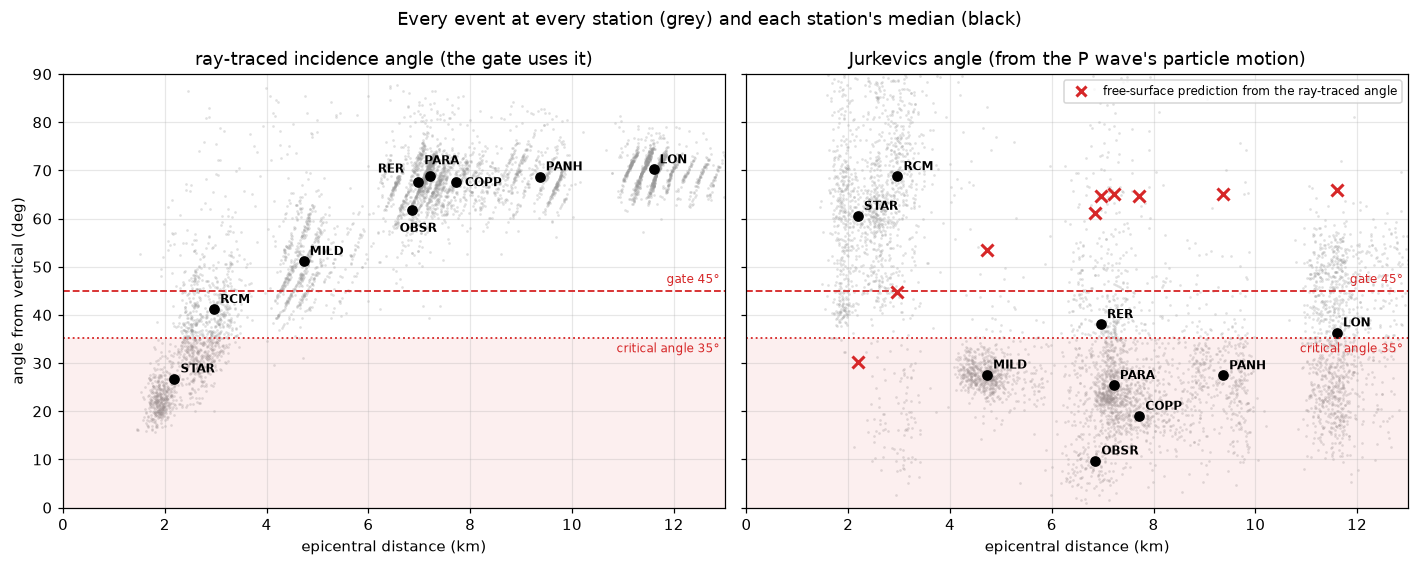

In [17]:
VP_VS = 1.73                                          # the research ray tracing's Vs = Vp / 1.73 (README)
CRITICAL = np.rad2deg(np.arcsin(1 / VP_VS))           # the critical angle, deg
GATE = quality.DEFAULT_PRE.incidence_max_deg
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True)
OFFSET = {("RER", "incidence_angle"): (-26, 6), ("PARA", "incidence_angle"): (-4, 8), ("COPP", "incidence_angle"): (6, -3),
          ("OBSR", "incidence_angle"): (-8, -14)}          # label positions that keep the names apart
rows = []
for s in STATIONS:
    geo = with_geometry(res[s], s)
    # the P wave's apparent angle at the free surface of a uniform half-space: sin(apparent / 2) = sin(ray angle) Vs / Vp
    apparent = 2 * np.rad2deg(np.arcsin(np.sin(np.deg2rad(geo.incidence_angle)) / VP_VS))
    x = geo.epicentral_km.median()
    for ax, col in zip(axes, ["incidence_angle", "incidence_angle_jurkevics"]):
        ax.scatter(geo.epicentral_km, geo[col], s=3, color="0.6", alpha=0.3, lw=0)
        ax.plot(x, geo[col].median(), "o", color="k", ms=6)
        ax.annotate(s, (x, geo[col].median()), xytext=OFFSET.get((s, col), (4, 4)), textcoords="offset points", fontsize=8, weight="bold")
    axes[1].plot(x, np.nanmedian(apparent), "x", color="tab:red", ms=8, mew=2)
    rows.append({"station": s, "epicentral km": x, "ray-traced": geo.incidence_angle.median(), "Jurkevics": geo.incidence_angle_jurkevics.median(),
                 "free-surface prediction": np.nanmedian(apparent),
                 "ray-traced inside gate": (geo.incidence_angle <= GATE).mean(), "Jurkevics inside gate": (geo.incidence_angle_jurkevics <= GATE).mean()})
for ax, title in zip(axes, ["ray-traced incidence angle (the gate uses it)", "Jurkevics angle (from the P wave's particle motion)"]):
    ax.axhspan(0, CRITICAL, color="tab:red", alpha=0.07, lw=0)
    ax.axhline(CRITICAL, color="tab:red", ls=":", lw=1.2); ax.axhline(GATE, color="tab:red", ls="--", lw=1.2)
    ax.text(12.9, CRITICAL - 1, f"critical angle {CRITICAL:.0f}°", ha="right", va="top", fontsize=8, color="tab:red")
    ax.text(12.9, GATE + 1, f"gate {GATE:.0f}°", ha="right", va="bottom", fontsize=8, color="tab:red")
    ax.set(xlabel="epicentral distance (km)", title=title, xlim=(0, 13), ylim=(0, 90))
axes[0].set_ylabel("angle from vertical (deg)")
axes[1].plot([], [], "x", color="tab:red", mew=2, label="free-surface prediction from the ray-traced angle")
axes[1].legend(fontsize=8, loc="upper right")
fig.suptitle("Every event at every station (grey) and each station's median (black)")
plt.tight_layout()
print(pd.DataFrame(rows).set_index("station").round(2).to_string())

**The ray-traced angles behave as geometry demands; the Jurkevics angles do not.** In the left panel each station's angles grow with distance, and the stations line up from STAR (2.2 km, median 27 degrees, 71 percent of its events inside the gate) through RCM (41 degrees) and MILD (51) to the flank stations at 62 to 70 degrees, none of which has more than 1 percent of its events inside the gate. In the right panel the order is reversed: the two summit stations, the closest, have the *shallowest* Jurkevics angles (STAR 61, RCM 69 degrees), and the flank stations the steepest (10 to 38 degrees), so by the Jurkevics angle 95 to 99 percent of PANH's, PARA's, OBSR's and COPP's events would pass the gate.

**The free surface explains only a few degrees.** The red crosses are what a uniform half-space with Vp/Vs = 1.73 predicts the P wave's apparent angle to be, given the ray-traced angle: a little shallower than the ray for steep rays (STAR 30 against 27 degrees) and a little steeper for shallow ones (LON 66 against 70). The sign of that effect matches the pattern, but the observed differences are eight to ten times larger (STAR +34, LON -34 degrees). The Jurkevics angle is measured in a 0.12 s window on unfiltered data, and at these short distances that window may contain more than the direct P wave (scattered energy, the P coda, topography's effect on the local free surface); the README lists STAR's large Jurkevics angles as not yet explained.

So whether PANH and the other flank stations have usable data depends entirely on which angle you believe, and neither has been validated. The ray-traced angle at least behaves like a ray; the velocity model behind it is the thing to test (exercise 4 finds its travel times too long at the summit). Raising the gate is notebook 07's question, with one warning from section 4: beyond the critical angle the free surface distorts S, so a rescued event is not a valid one.

### Exercise 4: what is a station's percent anisotropy made of?

The step of each station's dt values comes from the data (`dt_grid` of section 8), and `measure.DT_STEP_SAMPLES` turns it into the sampling rate it implies. The observed travel time comes from the strict catalog through `with_geometry`.

In [18]:
rows = []
for s in MEASURED:
    geo = with_geometry(res[s], s)
    kept = quality.post_filtered(geo)
    step = dt_grid(res[s])
    rows.append({"station": s, "N": len(kept), "dt step (s)": step, "implied sampling rate (Hz)": measure.DT_STEP_SAMPLES / step,
                 "one step (% points)": 100 * step / kept.travel_time_s.median(), "median dt (steps)": kept.dt.median() / step,
                 "model / observed travel time": (kept.travel_time_s / kept.s_travel_obs).median(),
                 "mean % (model time)": kept.pct_anisotropy.mean(), "mean % (observed time)": (100 * kept.dt / kept.s_travel_obs).mean()})
    print(f"{s}: dt (s) and count", kept.dt.round(2).value_counts().sort_index().to_dict(),
          "; most common bands", kept.filter_band.value_counts().head(3).to_dict())
print(pd.DataFrame(rows).set_index("station").round(2).to_string(), "\n")

star = quality.post_filtered(res["STAR"])
for name, band in [("1-5 Hz", "(1.0, 5.0)"), ("5-10 Hz", "(5.0, 10.0)")]:
    a = star[star.filter_band == band].pct_anisotropy.to_numpy()
    mean, lo, hi, _ = stats.bootstrap(a, np.mean)
    print(f"STAR at {name}: N = {len(a)}, percent anisotropy mean {mean:.2f} (68%: {lo:.2f} to {hi:.2f}), median {np.median(a):.2f}")

STAR: dt (s) and count {0.02: 43, 0.04: 12, 0.06: 116, 0.08: 23} ; most common bands {'(1.0, 5.0)': 136, '(5.0, 10.0)': 31, '(3.0, 5.0)': 10}
RCM: dt (s) and count {0.02: 1, 0.04: 12, 0.06: 14, 0.08: 4, 0.1: 1} ; most common bands {'(1.0, 5.0)': 21, '(3.0, 5.0)': 9, '(2.0, 8.0)': 1}
MILD: dt (s) and count {0.04: 21, 0.08: 3} ; most common bands {'(1.0, 8.0)': 11, '(1.0, 5.0)': 8, '(2.0, 8.0)': 2}
LON: dt (s) and count {0.02: 32, 0.04: 4, 0.06: 1, 0.1: 1} ; most common bands {'(5.0, 10.0)': 9, '(5.0, 15.0)': 7, '(3.0, 15.0)': 6}
           N  dt step (s)  implied sampling rate (Hz)  one step (% points)  median dt (steps)  model / observed travel time  mean % (model time)  mean % (observed time)
station                                                                                                                                                                 
STAR     194         0.02                       100.0                 1.10                3.0                          1.39     

RCM looks the "most anisotropic" (mean 3.40 percent), then STAR (2.93), MILD (2.19) and LON (0.68). Do not believe the ranking yet; look at what the numbers are made of:

- **Steps.** STAR, RCM and LON report dt in steps of 0.02 s, MILD in steps of 0.04 s, which `measure.dt_step` gives for a sampling rate of 50 Hz. MILD records on broadband `BH` channels (`data/catalog/channel_orientations.csv`), so 50 samples a second is likely; the repo has neither MILD's waveforms nor its StationXML, so this is inferred from the delays. The median delay is three steps at STAR and RCM and one step at MILD and LON, so MILD's and LON's values are the smallest delay their data can report: 21 of MILD's 24 delays are 0.04 s and 32 of LON's 38 are 0.02 s.
- **The band.** At STAR, the 136 events filtered at 1-5 Hz have a mean percent anisotropy of 3.42 (68 percent interval 3.36 to 3.48) and the 31 at 5-10 Hz 1.24 (1.18 to 1.31): a factor of almost three between two bands of the same station, the same rock and the same weeks. LON's events were filtered mostly in bands at and above 5-10 Hz, RCM's at 1-5 and 3-5 Hz, so part of the ranking is a ranking of bands. Whether that is frequency-dependent anisotropy or a limit of the measurement at short periods (notebook 03, section 8) is open.
- **The travel time.** `travel_time_s` comes from the velocity model, and at the summit stations it is much longer than the observed S travel time: 1.39 times at STAR, 1.26 at RCM, 1.13 at MILD and 1.04 at LON (medians). With the observed times, the means become 4.12 percent at STAR, 4.35 at RCM, 2.48 at MILD and 0.71 at LON. The order stays, but the summit values rise by 30 to 40 percent. The excess is largest for the rays that cross the upper edifice, which suggests the model is too slow there (or that the model's and the catalog's depths and origin times differ); either way, percent anisotropy at the summit inherits it. That is worth raising with Michael.

So these numbers say "about 1 to 4 percent", with every station's value a small whole number of steps divided by a travel time that is itself uncertain at the summit. A fair comparison between stations needs the same band, the same step and observed (or validated) travel times.

### Exercise 5: is the rise of dt during the swarm a band artifact?

mean dt of each band over the swarm (s): {'1-5 Hz': 0.061, '5-10 Hz': 0.022, 'other bands': 0.044}
            N  share 1-5 Hz  dt, all bands     SE  predicted from the mix  N 1-5 Hz  dt, 1-5 Hz  SE 1-5 Hz
period                                                                                                    
Jul 8      28         0.286          0.036  0.004                   0.037         8       0.062      0.003
Jul 9-10   59         0.729          0.050  0.002                   0.054        43       0.057      0.002
Jul 11-14  50         0.740          0.058  0.002                   0.055        37       0.063      0.001
Jul 15-21  45         0.867          0.059  0.002                   0.056        39       0.064      0.001
Jul 22 on  12         0.750          0.053  0.006                   0.053         9       0.058      0.005 

axial mean phi per period, deg (68% bootstrap interval):


                   all bands         1-5 Hz only       5-10 Hz only
period                                                             
Jul 8       43.2 (-3.2/+3.3)   37.6 (-7.3/+11.1)   43.7 (-3.2/+3.4)
Jul 9-10    33.6 (-2.1/+2.1)    33.4 (-1.7/+1.9)   38.3 (-5.2/+5.1)
Jul 11-14   30.4 (-1.5/+1.5)    31.4 (-0.8/+0.9)   29.6 (-2.5/+2.5)
Jul 15-21   30.6 (-1.2/+1.1)    30.4 (-1.1/+1.2)   31.3 (-3.9/+3.2)
Jul 22 on   41.2 (-3.3/+3.4)    37.5 (-3.4/+3.8)   52.5 (-6.1/+6.1)
axial mean phi of each band over the swarm (deg): {'1-5 Hz': 32.3, '5-10 Hz': 39.7, 'other bands': 33.9}


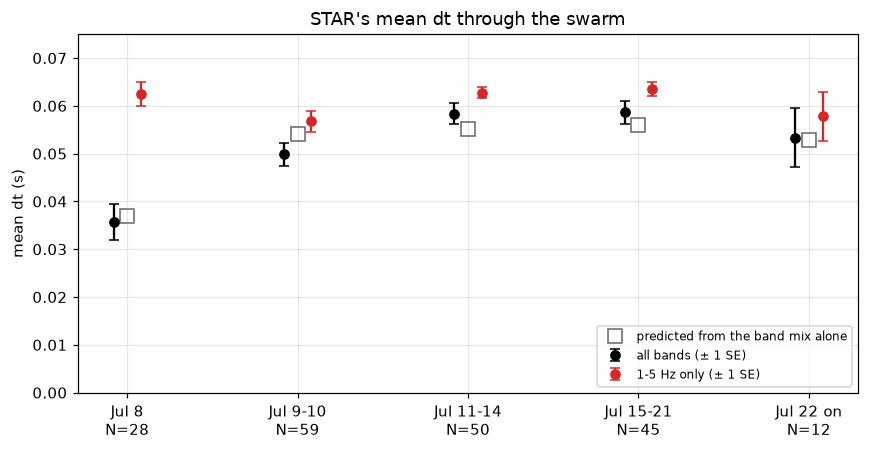

In [19]:
band_dt = swarm.groupby("band").dt.mean()                       # each band's mean dt over the whole swarm
mix = pd.crosstab(swarm.period, swarm.band, normalize="index")  # each period's band mix
table = pd.DataFrame({
    "N": swarm.groupby("period", observed=True).dt.size(),
    "share 1-5 Hz": mix["1-5 Hz"],
    "dt, all bands": swarm.groupby("period", observed=True).dt.mean(),
    "SE": swarm.groupby("period", observed=True).dt.sem(),
    "predicted from the mix": mix @ band_dt,
    "N 1-5 Hz": swarm_low.groupby("period", observed=True).dt.size(),
    "dt, 1-5 Hz": swarm_low.groupby("period", observed=True).dt.mean(),
    "SE 1-5 Hz": swarm_low.groupby("period", observed=True).dt.sem(),
})
print("mean dt of each band over the swarm (s):", band_dt.round(3).to_dict())
print(table.round(3).to_string(), "\n")

def axial_mean_68(phi):
    m, lo, hi, _ = stats.bootstrap_axial_mean(phi)
    return f"{m:5.1f} ({lo:+.1f}/{hi:+.1f})"
print("axial mean phi per period, deg (68% bootstrap interval):")
print(pd.DataFrame({"all bands": swarm.groupby("period", observed=True).phi.apply(axial_mean_68),
                    "1-5 Hz only": swarm_low.groupby("period", observed=True).phi.apply(axial_mean_68),
                    "5-10 Hz only": swarm[swarm.band == "5-10 Hz"].groupby("period", observed=True).phi.apply(axial_mean_68)}).to_string())
print("axial mean phi of each band over the swarm (deg):", {b: round(stats.axial_mean(p)[0], 1) for b, p in swarm.groupby("band").phi})

fig, ax = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(table))
ax.errorbar(x - 0.08, table["dt, all bands"], yerr=table.SE, fmt="o", color="k", capsize=3, label="all bands (± 1 SE)")
ax.plot(x, table["predicted from the mix"], "s", mfc="none", mec="0.4", ms=9, label="predicted from the band mix alone")
ax.errorbar(x + 0.08, table["dt, 1-5 Hz"], yerr=table["SE 1-5 Hz"], fmt="o", color="tab:red", capsize=3, label="1-5 Hz only (± 1 SE)")
ax.set(xticks=x, xticklabels=[f"{p}\nN={n}" for p, n in zip(table.index, table.N)], ylabel="mean dt (s)", ylim=(0, 0.075),
       title="STAR's mean dt through the swarm")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()

**Yes, for dt.** The pooled mean rises from 0.036 ± 0.004 s on 8 July (N = 28) to 0.058 ± 0.002 s on 11 to 14 July (N = 50) and 0.059 on 15 to 21 July: about five standard errors. The band mix alone, with each band's swarm-wide mean (0.061 s at 1-5 Hz, 0.022 at 5-10 Hz, 0.044 for the other bands), predicts 0.037, 0.054, 0.055, 0.056 and 0.053 s for the five periods, within about one to two standard errors of every measured value. And the 1-5 Hz events alone stay between 0.057 and 0.064 s in every period, 0.062 s on 8 July. There is no sign of a change of dt within a band; the change is in which band the filter bank chose (notebook 03, exercise 3, asks why that changed).

**Partly, for phi.** The pooled axial mean is 43 degrees on 8 July (68 percent interval about ± 3) and 30 to 34 from 9 to 21 July. Over the whole swarm the 5-10 Hz events point at 40 degrees and the 1-5 Hz events at 32, so the 8 July mix, with half its events at 5-10 Hz, pulls the pooled mean east. Within 1-5 Hz the 8 July mean is 38 degrees, but from only 8 events (interval -7 to +11), against 30 to 33 degrees from 9 to 21 July; within 5-10 Hz it is 44 degrees on 8 July (15 events) against 30 to 38 on 9 to 21 July. So a few degrees of change may remain within each band, at the edge of what these intervals can resolve, and those intervals treat the 28 events of one day as independent. Deciding whether that remainder is real is exactly notebook 07's permutation test within one band.

### Exercise 6: stress or structure?

In [20]:
rows = []
for s in MEASURED:
    kept = quality.post_filtered(res[s])
    m, lo, hi, _ = stats.bootstrap_axial_mean(kept.phi)
    _, R = stats.axial_mean(kept.phi)
    dist, radial, _ = gps2dist_azimuth(summit[0], summit[1], sta.loc[s, "lat"], sta.loc[s, "lon"])   # summit -> station
    rows.append({"station": s, "N": len(kept), "mean phi": m, "68% interval": f"{lo:+.1f}/{hi:+.1f}", "R": R,
                 "off compression": stats.axial_diff(m, reference.REGIONAL_COMPRESSION_AZ),
                 "off 2009 structure": stats.axial_diff(m, reference.STRUCTURE_2009_STRIKE),
                 "km from summit": dist / 1e3, "off radial": stats.axial_diff(m, radial),
                 "off back azimuth": stats.axial_diff(m, kept.back_azimuth.median())})
print(pd.DataFrame(rows).set_index("station").to_string(float_format=lambda v: f"{v:.1f}", formatters={"R": "{:.2f}".format}))
m, lo, hi, _ = stats.block_bootstrap_axial_mean(swarm.phi, swarm.time.dt.floor("D"))
print(f"\nSTAR, resampling whole days instead of single events: {m:.1f} deg, 68% interval {lo:+.1f}/{hi:+.1f}")

           N  mean phi 68% interval    R  off compression  off 2009 structure  km from summit  off radial  off back azimuth
station                                                                                                                    
STAR     194      33.7    -0.9/+1.0 0.86             11.3                11.3             2.5        51.1              59.1
RCM       32     151.2    -3.1/+2.8 0.85             73.8                73.8             2.8        18.3              24.3
MILD      24     110.4    -4.7/+6.2 0.42             65.4                65.4             5.1        82.8              77.8
LON       38       7.4    -3.3/+3.3 0.65             37.6                37.6            12.0        10.9               8.8

STAR, resampling whole days instead of single events: 33.7 deg, 68% interval -1.8/+1.9


**At STAR the azimuth cannot decide; elsewhere it argues against one regional cause.**

- **STAR**: 33.7 degrees, with a 68 percent interval of about ±1 degree resampling events, ±1.9 resampling whole days (notebook 07 explains the difference), 11 degrees from both reference directions. Eleven degrees is many intervals, but the reference directions are themselves approximate ("about NE"), and since they point the same way, STAR fits both hypotheses equally.
- **RCM** (151 degrees, interval about ±3) and **MILD** (110, -5 to +6, R = 0.42) are 74 and 65 degrees from both references, and **LON** (7, ±3) is 38 degrees from them. Neither the regional stress nor the 2009 structure, applied everywhere, explains them.

**The radial check does not give a simple pattern either.** RCM's mean is 18 degrees from its radial direction and LON's 11, but STAR's is 51 and MILD's 83 (nearly tangential). And the check is not clean: because the swarm sits under the summit, the radial direction is almost the same as the back-azimuth direction at every station (compare the last two columns). A fast direction along the radial direction is therefore also a fast direction along the rays, the signature of an artifact (section 7). With earthquakes in one place only, the two cannot be separated.

**What could separate stress from structure**, following section 4's table:

- *Between stations*: the differences here, tens of degrees between stations a few kilometres apart, are what local control predicts. To test it, compare each station's fast direction with the structures the relocated 2025 seismicity reveals near it (step 3 of the research plan), and first make sure each station's measurement is sound (exercises 2 and 4, notebook 07).
- *Through time*: a stress-controlled fast direction can rotate as fluid pressure changes; a structural one should not. Section 9 and exercise 5 show what a fair test has to compare (one band at a time); notebook 07 makes it.
- *Between swarms*: the same station in 2009 and 2025 (README, Winter quarter, project 2).
- *More geometry*: earthquakes away from the summit, or the nodes, to separate a radial pattern from the rays.

Whether the differences between stations are larger than their uncertainties is formally notebook 07's question too, although differences of 40 to 75 degrees against intervals of a few degrees leave little doubt for this sample.

### Exercise 7 (stretch): does phi depend on back azimuth?

Fit the line to phi measured from its axial mean, so that the jump between 0 and 180 degrees does not matter, and bootstrap the slope by resampling events (`stats.bootstrap` on the event indices).

all bands N = 194: median back azimuth  92.8 deg, axial mean phi  33.7 deg, slope -0.26 deg per deg (68%: -0.46 to -0.09)
1-5 Hz    N = 136: median back azimuth  94.2 deg, axial mean phi  32.3 deg, slope +0.00 deg per deg (68%: -0.23 to +0.18)


5-10 Hz   N =  31: median back azimuth  87.7 deg, axial mean phi  39.7 deg, slope -0.10 deg per deg (68%: -0.35 to +0.17)


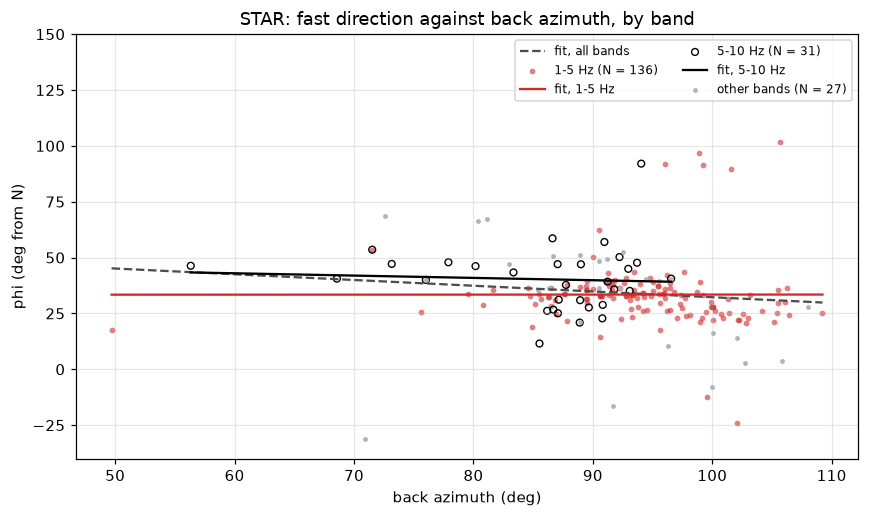

In [21]:
def phi_slope(sub):
    """Slope of phi (measured from its axial mean, deg) against back azimuth, deg per deg, with a 68 percent bootstrap interval."""
    m, _ = stats.axial_mean(sub.phi)
    y = (np.mod(sub.phi - m + 90, 180) - 90).to_numpy()
    x = sub.back_azimuth.to_numpy()
    slope, lo, hi, _ = stats.bootstrap(np.arange(len(x)), lambda i: np.polyfit(x[i], y[i], 1)[0])   # resample events
    return m, y, slope, lo, hi

fig, ax = plt.subplots(figsize=(8, 4.8))
m_all, _, *_ = phi_slope(swarm)
for name, sub, kw in [("all bands", swarm, dict(color="0.65", s=10, lw=0)),
                      ("1-5 Hz", swarm_low, dict(color="tab:red", s=14, alpha=0.6, lw=0)),
                      ("5-10 Hz", swarm[swarm.band == "5-10 Hz"], dict(facecolors="none", edgecolors="k", s=20, lw=0.9))]:
    m, y, slope, lo, hi = phi_slope(sub)
    print(f"{name:9s} N = {len(sub):3d}: median back azimuth {sub.back_azimuth.median():5.1f} deg, axial mean phi {m:5.1f} deg, "
          f"slope {slope:+.2f} deg per deg (68%: {lo:+.2f} to {hi:+.2f})")
    if name != "all bands":
        ax.scatter(sub.back_azimuth, np.mod(sub.phi - m_all + 90, 180) - 90 + m_all, label=f"{name} (N = {len(sub)})", **kw)
    xs = np.array([sub.back_azimuth.min(), sub.back_azimuth.max()])
    b = np.polyfit(sub.back_azimuth, y, 1)
    ax.plot(xs, np.polyval(b, xs) + m, color={"all bands": "0.3", "1-5 Hz": "tab:red", "5-10 Hz": "k"}[name],
            ls="--" if name == "all bands" else "-", lw=1.5, label=f"fit, {name}")
other = swarm[swarm.band == "other bands"]
ax.scatter(other.back_azimuth, np.mod(other.phi - m_all + 90, 180) - 90 + m_all, color="0.7", s=10, lw=0, label=f"other bands (N = {len(other)})")
ax.set(xlabel="back azimuth (deg)", ylabel="phi (deg from N)", ylim=(-40, 150), title="STAR: fast direction against back azimuth, by band")
ax.legend(fontsize=8, ncol=2, loc="upper right")
plt.tight_layout()

**Pooled, phi seems to depend on back azimuth; within each band it does not.** All 194 events give a slope of -0.26 degrees per degree (68 percent interval -0.46 to -0.09), which across the 60 degrees of back azimuth would mean about 15 degrees of rotation. Within the 136 events at 1-5 Hz the slope is +0.00 (-0.23 to +0.18), and within the 31 at 5-10 Hz -0.10 (-0.35 to +0.17): no dependence in either.

The pooled slope comes from mixing the bands. The 5-10 Hz events arrive from slightly smaller back azimuths (median 88 degrees against 94 for 1-5 Hz, a difference of about 250 m in epicentre at STAR's distance) and have fast directions about 7 degrees further east (40 against 32). Put both groups on one plot and a line through them slopes downwards, although neither group slopes by itself. The same trap as section 9's dt, in a different variable: whenever a quantity depends on the band, and the band mix varies with something else (time, back azimuth, magnitude, incidence angle), the pooled data show a dependence on that something else. Check within one band before reading physics into a trend.

Why the 5-10 Hz events point further east is open: frequency-dependent anisotropy (notebook 03, section 8), or paths from a slightly different part of the swarm. A project for later.